# ¿Cuánto aviso nos da un río? · 08 — Comparación integrada y selección final

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py`; identificado como `v4` en el código y en las salidas), aplicado con `integrado.py`, el mismo módulo de los cuadernos 05 y 06. La fecha de ejecución y las versiones de software se imprimen en la celda de configuración.

**Lugar en el estudio:** este cuaderno responde la pregunta **P6**: la **comparación integrada y la selección final del proyecto**. En las mismas emisiones se comparan los **seis modelos entrenados** (regresión lineal, KNN, Random Forest, XGBoost, MLP y LSTM) y **Chronos-2** (preentrenado, sin ajuste local) con todas las combinaciones de entradas disponibles en cada cuenca, y se elige en validación, por cuenca, periodo de prueba y disponibilidad de los datos, **una configuración para la magnitud del caudal** y **una para la anticipación de crecidas**, que después se evalúan en la prueba sin cambiarlas. Los cuadernos 05 (caudal aguas arriba) y 06 (lluvia) estudian cada fuente por separado y entrenan sus combinaciones, y el 07 prepara las predicciones de Chronos-2; aquí se reutilizan solo si su identidad experimental coincide, y se entrenan las combinaciones que no pertenecen a ninguno de ellos (lluvia e índices junto con San Regis, Requena o ambas).

**Alcance:** es una **comparación académica de configuraciones** evaluadas retrospectivamente, no un sistema operativo de alerta. Las familias reciben las mismas fuentes con la misma disponibilidad, pero cada una con su propia representación (sección 3).

**Sobre el periodo de prueba:** las reglas de selección se fijaron antes de la evaluación final y la prueba no interviene en ninguna elección (la sección 9 lo comprueba reemplazándola por ruido), pero el periodo de prueba (desde 2016-01) se consultó durante el desarrollo del proyecto con casi todas estas entradas: no es una prueba ciega.

---

## 0. Objetivo y diseño

### 0.1 Preguntas
1. **Magnitud:** ¿qué modelo y qué entradas se eligen en validación para pronosticar el caudal diario a 1–30 días en cada cuenca, según la información disponible el día de emisión, y cómo rinde esa elección en la prueba?
2. **Anticipación de crecidas:** ¿qué configuración se elige en validación para avisar de nuevos cruces del P95, y cumple los criterios de utilidad del cuaderno 04 en la prueba?
3. ¿La selección es nítida? ¿Cuántos candidatos son equivalentes al mejor en validación y cuántos quedan inconclusos (sin evidencia para ordenarlos)? ¿Coincide lo elegido en validación con lo mejor observado en la prueba?

### 0.2 Candidatos por cuenca
| Cuenca | Combinaciones de entradas (cada una con las fuentes externas hasta t y hasta t−1) | Familias | Estaciones aguas arriba |
|---|---|---|---|
| **Racarumi** (2 363 km²) | Q; Q+P; Q+P+IA | seis modelos + Chronos-2 | **Cirato** no entra: solo tiene 13 meses con fechas confiables (2022-08 a 2023-08), sin entrenamiento ni validación del protocolo; queda como análisis exploratorio (05 §10 y 07 §8) |
| **Tamshiyacu** (~720 000 km²) | las 12 combinaciones de {—, P, P+IA} × {—, SR, RQ, SR+RQ}: Q; Q+P; Q+P+IA; Q+SR; Q+P+SR; Q+P+IA+SR; Q+RQ; Q+P+RQ; Q+P+IA+RQ; Q+SR+RQ; Q+P+SR+RQ; Q+P+IA+SR+RQ | seis modelos + Chronos-2 | **San Regis** (SR, Marañón) y **Requena** (RQ, Ucayali), cada una con su registro; no se tratan como intercambiables |

Q: caudal local (nivel de hoy y 29 cambios diarios) y calendario; P: lluvia de la cuenca (siete valores diarios y tres acumulados hasta 90 días); IA: índices antecedentes (IPA con k = 0.90 y 0.97 y días secos); SR, RQ: caudal de la estación con la misma ventana que el local. **No implementadas** (se documentan en la matriz de experimentos): los índices antecedentes sin la lluvia (por diseño, IA se agrega sobre P) y cualquier combinación con Cirato en el protocolo principal. El control Q+Pd de Racarumi (06) y la lluvia futura observada (experimento idealizado del 06 y el 07) **no compiten**.

### 0.3 Protocolo común (fijado antes de evaluar)
| Paso | Decisión |
|---|---|
| Emisiones | Racarumi: las del cuaderno 06 (todas las configuraciones con ventanas válidas). Tamshiyacu: las del cuaderno 05 (San Regis válida en t y t−1; en entrenamiento y validación, también Requena). Se comprueba que son idénticas a las guardadas por 05 y 06. |
| División | Entrenamiento hasta 2008; validación 2009–2015 (Duan 2009–2011; selección 2012–2015); prueba desde 2016-01 hasta el fin de cada registro. La LSTM detiene con 2005–2008. Climatología de referencia hasta 2015. |
| Periodos de prueba | Racarumi: **prueba 2016-01 a 2023-08**. Tamshiyacu: **con San Regis (prueba 2016-01 a 2025-12)**, candidatos sin Requena; y **común con Requena (prueba 2016-01 a 2020-03)**, emisiones con Requena válida hasta t y hasta t−1, todos los candidatos en las mismas emisiones. Las etiquetas se generan con los meses reales de las emisiones (§2). Cada selección se evalúa solo en su periodo. |
| Escenarios de disponibilidad | **Mismo día**: fuentes externas hasta t (supuesto optimista). **Un día de retraso**: hasta t−1. El caudal local siempre llega hasta t; Q compite en los dos. |
| Selección para la magnitud | Bloque 2012–2015, regla de selección del estudio: mayor NSE medio de los 30 horizontes; IC 90 % por bootstrap pareado de meses; la más simple entre la mayor y sus **equivalentes** (IC 90 % de la diferencia dentro de ±0.01). Un candidato **inconcluso** (IC demasiado ancho para afirmar equivalencia, mejora o pérdida) no es equivalente ni indistinguible: no se elige por simple y se informa aparte. Simplicidad: menos fuentes externas, después el orden de las combinaciones y después el modelo (regresión lineal, KNN, Random Forest, XGBoost, MLP, LSTM, Chronos-2). |
| Selección para avisos | Protocolo común de 04 y 06 (`comun.seleccion_avisos`): regla (f, h_max) calibrada en 2009–2011, candidatos comparados en 2012–2015 (mayor CSI con FAR ≤ 0.5; empate: el más simple), regla final recalibrada en toda la validación. Solo donde hay cruces para calibrar, comparar y evaluar (Racarumi). |
| Prueba | Sin cambiar la selección: NSE por horizonte, horizonte útil (cota 95 % del bootstrap conjunto por meses), ΔNSE con IC 90 % frente a solo caudal y frente a los demás candidatos; avisos con IC de Wilson al 90 %, anticipación útil y omisiones. |
| Criterios de utilidad | **Magnitud:** horizonte útil con cota 95 % ≥ 1 día (NSE > 0 y habilidad frente a persistencia y climatología hasta ese horizonte). **Avisos:** anticipación útil ≥ 1 día (POD(A) ≥ 0.5 con FAR ≤ 0.5) y, con más exigencia, también con los IC de Wilson. Se admite que ninguna configuración los cumpla. |
| Reutilización | Ajustes de los seis modelos: caché de `entradas.py` con identidad completa (datos, filas, partición, malla, semillas, software y código); los de 05 y 06 se leen sin reentrenar (si falta uno, el cuaderno se detiene). Chronos-2: predicciones del 07 (cachés verificadas por identidad, contenido y reproducción de una muestra), alineadas por fecha; se comprueba explícitamente que cubren el bloque de selección y la prueba de cada combinación. |

---
## 1. Configuración
Librerías, semillas y rutas relativas; comprobación de que las salidas de las etapas anteriores son compatibles (mismo protocolo, ejecución final) y carga de las predicciones guardadas por 05, 06 y 07.

In [1]:
import os, sys, json, time, warnings, platform, subprocess, dataclasses
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost, torch

import comun as C
import aguas_arriba as A
import entradas as EN
import integrado as I

%matplotlib inline
warnings.filterwarnings('ignore')
np.random.seed(C.SEMILLA)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

RAPIDO = os.environ.get('CDA_RAPIDO') == '1'
if RAPIDO:
    C.MALLAS = {k: {kk: vv[:1] for kk, vv in v.items()} for k, v in C.MALLAS.items()}
    C.SEMILLAS = C.SEMILLAS[:1]
B = 50 if RAPIDO else 1000

SAL = C.ruta_salidas()
RUTA_SAL = SAL / 'entradas'
PREVIAS = {k: C.verificar_resumen(SAL / k / 'resumen.json') for k in ['tamshiyacu', 'racarumi', 'anticipacion', 'aguas_arriba', 'lluvia', 'chronos']}
RUTA_FIG, RUTA_TAB = RUTA_SAL / 'figuras', RUTA_SAL / 'tablas'
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)

EST = ['Racarumi', 'Tamshiyacu']
MODELOS, CAND_M, CH = I.MODELOS, I.ORDEN_MODELOS, I.CHRONOS          # seis modelos; seis + Chronos-2
SR, RQ = EN.SR, EN.RQ
AV = C.AVISO
Z05 = np.load(SAL / 'aguas_arriba' / 'predicciones.npz')
Z06 = np.load(SAL / 'lluvia' / 'predicciones.npz')
ZC = np.load(SAL / 'chronos' / 'predicciones.npz')
T_INICIO = time.time()
VERIF = []
def verificar(grupo, comprobacion, ok, detalle=''):
    VERIF.append({'grupo': grupo, 'comprobación': comprobacion, 'resultado': 'correcto' if ok else 'FALLA', 'detalle': detalle})
    assert ok, f'{grupo}: {comprobacion} ({detalle})'

print(f"Ejecutado: {datetime.now():%Y-%m-%d %H:%M} | protocolo {C.VERSION} | modo rápido: {RAPIDO}")
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | torch {torch.__version__}")
print('Chronos-2: contexto ' + ', '.join(map(str, ZC['contexto'])) + ' | resumen puntual ' + ', '.join(map(str, ZC['punto'])))

Ejecutado: 2026-11-22 23:24 | protocolo v4 | modo rápido: False
Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.1.2 | torch 2.14.1+cu130
Chronos-2: contexto Racarumi:2048, Tamshiyacu:512 | resumen puntual Racarumi:media, Tamshiyacu:media


---
## 2. Emisiones y correspondencia con los cuadernos 05 y 06
El experimento integrado de cada cuenca (`entradas.DISENO_INTEGRADO`) usa fechas de validación, de bloque de selección y de prueba **idénticas** a las guardadas por el cuaderno que entrenó cada combinación (06 en Racarumi, 05 en Tamshiyacu); se comprueba fecha por fecha. Aquí se definen los periodos de prueba de cada selección, nombrados con los meses reales de sus emisiones.

In [2]:
X = {e: I.cargar(e, EN.DISENO_INTEGRADO) for e in EST}
xR, xT = X['Racarumi'], X['Tamshiyacu']
d64 = lambda f: pd.DatetimeIndex(f).values.astype('datetime64[D]')
for e, Z, nb in [('Racarumi', Z06, '06'), ('Tamshiyacu', Z05, '05')]:
    x = X[e]
    verificar('correspondencia de fechas', f'{e}: validación = cuaderno {nb}', np.array_equal(d64(x.fechas_val), Z[f'{e}|fechas_val']), f'{len(x.fechas_val)} emisiones')
    verificar('correspondencia de fechas', f'{e}: bloque de selección = cuaderno {nb}', np.array_equal(d64(x.VC.fechas_sel), Z[f'{e}|fechas_sel']), f'{len(x.VC.sel)} emisiones')
    verificar('correspondencia de fechas', f'{e}: prueba = cuaderno {nb}', np.array_equal(d64(x.m.fechas[x.p['pru']]), Z[f'{e}|Q|fechas_pru']), f"{len(x.p['pru'])} emisiones")
IP_RQ = I.comunes(*[xT.D[k].ip for k in xT.D if RQ in k[0]])          # Requena válida hasta t y hasta t−1 (la del 05)
verificar('correspondencia de fechas', 'Tamshiyacu: prueba común con Requena = cuaderno 05', np.array_equal(d64(xT.m.fechas[IP_RQ]), Z05['Tamshiyacu|fechas_pru_requena']), f'{len(IP_RQ)} emisiones')

def rango(x, idx):
    f = x.m.fechas[idx]
    return f"{f.min():%Y-%m-%d} a {f.max():%Y-%m-%d}"
# las etiquetas de cada periodo de prueba se construyen con los meses reales de sus emisiones
ALC_R = I.etiqueta_periodo(xR, xR.p['pru'])                              # 'prueba 2016-01 a 2023-08'
ALC_SR = I.etiqueta_periodo(xT, xT.p['pru'], 'con San Regis')            # 'con San Regis (prueba 2016-01 a 2025-12)'
ALC_RQ = I.etiqueta_periodo(xT, IP_RQ, 'común con Requena')              # 'común con Requena (prueba 2016-01 a 2020-03)'
ALCANCES = {('Racarumi', ALC_R): (lambda c: True, xR.p['pru']),
            ('Tamshiyacu', ALC_SR): (lambda c: RQ not in c, xT.p['pru']),
            ('Tamshiyacu', ALC_RQ): (lambda c: True, IP_RQ)}
verificar('etiquetas', 'cada periodo de prueba se nombra con el primer y el último mes de sus emisiones',
          all(alc.endswith(f"{X[e].m.fechas[ip].max():%Y-%m}" + (')' if '(' in alc else '')) and f"{X[e].m.fechas[ip].min():%Y-%m}" in alc
              for (e, alc), (ok, ip) in ALCANCES.items()) and len(set(ALCANCES)) == 3, ' | '.join(f'{e}: {a}' for e, a in ALCANCES))
filas = []
for (e, alc), (ok, ip) in ALCANCES.items():
    x = X[e]
    filas.append({'estación': e, 'periodo de prueba de la selección': alc, 'entrenamiento': f"{len(x.p['ent'])} ({rango(x, x.p['ent'])})",
                  'validación': len(x.p['val']), 'Duan 2009–2011': len(x.VC.cal), 'selección 2012–2015': len(x.VC.sel),
                  'prueba': f'{len(ip)} ({rango(x, ip)})', 'P95 (m³/s)': round(x.P95, 1),
                  'combinaciones de entradas': ', '.join(I.etiqueta(c, l) for c, l in x.conjuntos if ok(c))})
div = pd.DataFrame(filas).set_index(['estación', 'periodo de prueba de la selección'])
div.to_csv(RUTA_TAB / 'tabla_division.csv')
div

entrenamiento  \
estación   periodo de prueba de la selección                                              
Racarumi   prueba 2016-01 a 2023-08                      9247 (1981-04-01 a 2008-12-01)   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)      2847 (1998-10-01 a 2008-12-01)   
           común con Requena (prueba 2016-01 a 2020-03)  2847 (1998-10-01 a 2008-12-01)   

                                                         validación  \
estación   periodo de prueba de la selección                          
Racarumi   prueba 2016-01 a 2023-08                            2371   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)            1928   
           común con Requena (prueba 2016-01 a 2020-03)        1928   

                                                         Duan 2009–2011  \
estación   periodo de prueba de la selección                              
Racarumi   prueba 2016-01 a 2023-08                                 972   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)                 760   
           común con Requena (prueba 2016-01 a 2020-03)             760   

                                                         selección 2012–2015  \
estación   periodo de prueba de la selección                                   
Racarumi   prueba 2016-01 a 2023-08                                     1369   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)                     1138   
           común con Requena (prueba 2016-01 a 2020-03)                 1138   

                                                                                 prueba  \
estación   periodo de prueba de la selección                                              
Racarumi   prueba 2016-01 a 2023-08                      2521 (2016-01-01 a 2023-08-01)   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)      2806 (2016-01-01 a 2025-12-01)   
           común con Requena (prueba 2016-01 a 2020-03)  1093 (2016-01-01 a 2020-03-31)   

                                                         P95 (m³/s)  \
estación   periodo de prueba de la selección                          
Racarumi   prueba 2016-01 a 2023-08                           111.2   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)         47602.8   
           común con Requena (prueba 2016-01 a 2020-03)     47602.8   

                                                                                 combinaciones de entradas  
estación   periodo de prueba de la selección                                                                
Racarumi   prueba 2016-01 a 2023-08                                Q, Q+P, Q+P (t−1), Q+P+IA, Q+P+IA (t−1)  
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)      Q, Q+P, Q+P (t−1), Q+P+IA, Q+P+IA (t−1), Q+SR,...  
           común con Requena (prueba 2016-01 a 2020-03)  Q, Q+P, Q+P (t−1), Q+P+IA, Q+P+IA (t−1), Q+SR,...

**Interpretación:**
- **Racarumi:** 9 247 emisiones de entrenamiento (1981-04 a 2008-12), 2 371 de validación (972 para Duan y 1 369 para la selección) y 2 521 de prueba (**prueba 2016-01 a 2023-08**), las mismas del cuaderno 06 (verificado fecha por fecha).
- **Tamshiyacu:** 2 847 de entrenamiento (1998-10 a 2008-12), 1 928 de validación (760 y 1 138) y dos periodos de prueba que no se mezclan: **con San Regis (prueba 2016-01 a 2025-12)**, 2 806 emisiones y las 11 combinaciones sin Requena; y **común con Requena (prueba 2016-01 a 2020-03)**, 1 093 emisiones y las 23 combinaciones. Las etiquetas se generan con el primer y el último mes de las emisiones (control del registro de verificaciones). Son las del cuaderno 05: todas las combinaciones, con o sin Requena y con o sin lluvia, se eligen en las mismas 1 138 emisiones de validación.
- **Lo que no se compara aquí:** Tamshiyacu con todas las emisiones de los modelos base (3 252 de prueba, sin exigir San Regis) es otra muestra; sus resultados con la lluvia están en el 06.

---
## 3. Candidatos: ajustes reutilizados, ajustes propios y Chronos-2
1. **Seis modelos.** Cada combinación pertenece al cuaderno que la estudia: 06 (Racarumi: Q, Q+P, Q+P+IA), 05 (Tamshiyacu: Q, Q+SR, Q+RQ, Q+SR+RQ) o este (Tamshiyacu: Q+P, Q+P+IA y sus combinaciones con San Regis, Requena o ambas, en las filas del 05). Las de 05 y 06 se **leen** de la caché con identidad completa (si alguna falta, el cuaderno se detiene en lugar de entrenarla aquí); las propias se ajustan con la malla, las semillas y la estrategia del protocolo (o se leen de la caché si ya se ajustaron con la misma identidad).
2. **Comprobación de identidad:** los pronósticos de validación y de prueba reconstruidos aquí deben ser iguales a los guardados por 05 y 06.
3. **Chronos-2:** sus pronósticos (contexto y resumen puntual elegidos en validación en el 07, pesos preentrenados sin ajuste; cachés verificadas por identidad, contenido y reproducción de una muestra) se alinean por fecha con las emisiones del experimento. Se comprueba explícitamente que cubren el bloque de selección y cada periodo de prueba en que compite la combinación, sin fechas duplicadas, con valores finitos y P10 ≤ mediana ≤ P90.
4. **Entradas reales:** una ficha por combinación y familia con lo que efectivamente recibe cada una (tabla de `entradas.inventario_entradas` para los seis modelos y la tabla de entradas del 07 para Chronos-2).

In [3]:
def cuaderno(e, conj, lat):
    if e == 'Racarumi':
        return '06'
    return '05' if (conj, lat) in EN.DISENO_ARRIBA['Tamshiyacu']['conjuntos'] else '08'
R, P, REG = {}, {}, []
for e in EST:
    x = X[e]
    ajenos = [k for k in x.conjuntos if cuaderno(e, *k) != '08']
    propios = [k for k in x.conjuntos if cuaderno(e, *k) == '08']
    R1, r1 = I.ajustar(x, conjuntos=ajenos, solo_cache=True)
    REG.append(r1.assign(**{'cuaderno que lo entrena': [cuaderno(e, *k[:2]) for k in R1]}))
    R[e] = dict(R1)
    if propios:
        R2, r2 = I.ajustar(x, conjuntos=propios)
        R[e].update(R2)
        REG.append(r2.assign(**{'cuaderno que lo entrena': '08'}))
    P[e] = I.pronosticos(x, R[e])
registro = pd.concat(REG, ignore_index=True)
registro.to_csv(RUTA_TAB / 'tabla_registro_ajustes.csv', index=False)

# Identidad: los pronósticos de las combinaciones de 05 y 06 deben ser los que esos cuadernos guardaron
dif = []
for e, Z, nb in [('Racarumi', Z06, '06'), ('Tamshiyacu', Z05, '05')]:
    for k, pr in P[e].items():
        if cuaderno(e, k[0], k[1]) != nb:
            continue
        base = f'{e}|{I.etiqueta(k[0], k[1])}|{k[2]}'
        dif.append({'estación': e, 'cuaderno': nb, 'configuración': I.nombre(k),
                    'máx. |Δ| validación (m³/s)': float(np.max(np.abs(pr['sel'] - Z[base + '|sel']))),
                    'máx. |Δ| prueba (m³/s)': float(np.max(np.abs(pr['pru'] - Z[base + '|media'])))})
dif = pd.DataFrame(dif)
tol = dif[['máx. |Δ| validación (m³/s)', 'máx. |Δ| prueba (m³/s)']].max(axis=1) / np.where(dif['estación'] == 'Racarumi', 1, 100)
verificar('reutilización', 'pronósticos de 05 y 06 reconstruidos = guardados (float32)', bool((tol < 1e-2).all()),
          f"{len(dif)} configuraciones; máx. |Δ| = {dif.iloc[:, 3:].max().max():.2e} m³/s")

# Chronos-2: predicciones del 07 alineadas por fecha
FALTAN = []
for e in EST:
    x = X[e]
    for conj, lat in x.conjuntos:
        k = f'{e}|{I.etiqueta(conj, lat)}'
        if f'{k}|punto' not in ZC.files:
            FALTAN.append(k); continue
        P[e][(conj, lat, CH)] = I.pronostico_externo(x, conj, lat, ZC[f'{k}|fechas'], ZC[f'{k}|punto'], ZC[f'{k}|mediana'],
                                                     ip=IP_RQ if RQ in conj else None)
verificar('Chronos-2', 'predicción del 07 para cada combinación del experimento', not FALTAN, ', '.join(FALTAN) or f"{sum(1 for e in EST for k in P[e] if k[2] == CH)} combinaciones")
# Cobertura y contenido comprobados explícitamente 
cob = []
for e in EST:
    x = X[e]
    for conj, lat in x.conjuntos:
        k = f'{e}|{I.etiqueta(conj, lat)}'
        if f'{k}|punto' not in ZC.files:
            continue
        f = pd.DatetimeIndex(ZC[f'{k}|fechas'])
        ips = [ip for (e2, alc), (ok, ip) in ALCANCES.items() if e2 == e and ok(conj)]   # periodos de prueba en que compite
        pu, me, p10, p90 = (ZC[f'{k}|{c}'] for c in ('punto', 'mediana', 'P10', 'P90'))
        cob.append(dict(estación=e, combinación=I.etiqueta(conj, lat), emisiones=len(f),
                        cubre_seleccion=bool(x.VC.fechas_sel.isin(f).all()), cubre_validacion=bool(x.fechas_val.isin(f).all()),
                        cubre_pruebas=bool(all(x.m.fechas[ip].isin(f).all() for ip in ips)), periodos=len(ips),
                        sin_duplicados=bool(f.is_unique and f.is_monotonic_increasing),
                        finitos=bool(all(np.isfinite(a).all() for a in (pu, me, p10, p90))),
                        P10_mediana_P90_ordenados=bool((p10 <= me + 1e-6).all() and (me <= p90 + 1e-6).all())))
cob = pd.DataFrame(cob)
cob.to_csv(RUTA_TAB / 'tabla_cobertura_chronos.csv', index=False)
cols_c = ['cubre_seleccion', 'cubre_pruebas', 'sin_duplicados', 'finitos', 'P10_mediana_P90_ordenados']
verificar('Chronos-2', 'sus fechas cubren el bloque de selección y cada periodo de prueba en que compite la combinación',
          len(cob) == sum(len(X[e].conjuntos) for e in EST) and bool(cob[['cubre_seleccion', 'cubre_pruebas']].all().all()),
          f"{len(cob)} combinaciones; {int(cob['periodos'].sum())} pares combinación × periodo de prueba")
verificar('Chronos-2', 'pronósticos sin fechas duplicadas, finitos y con P10 ≤ mediana ≤ P90',
          bool(cob[['sin_duplicados', 'finitos', 'P10_mediana_P90_ordenados']].all().all()), f'{len(cob)} combinaciones')
verificar('Chronos-2', 'el 07 validó contenido y reproducción de cada caché reutilizada',
          bool(not (PREVIAS['chronos']['auditoria_cache']['dif_relativa_max_reproduccion'] > 2e-3)
               and 'cachés verificadas (incluye contexto)' in PREVIAS['chronos']['auditoria_cache']),
          f"{PREVIAS['chronos']['auditoria_cache']['cachés verificadas (incluye contexto)']} cachés reutilizadas; dif. relativa máx. {PREVIAS['chronos']['auditoria_cache']['dif_relativa_max_reproduccion']:.1e}")
print(f"Ajustes de los seis modelos: {len(registro)} (leídos de la caché: {int(registro['leído de la caché'].sum())}; "
      f"minutos de ajuste registrados: {registro['minutos de ajuste'].sum():,.0f})")
registro.groupby(['estación', 'cuaderno que lo entrena', 'leído de la caché']).size().rename('ajustes').to_frame()

Ajustes de los seis modelos: 168 (leídos de la caché: 168; minutos de ajuste registrados: 289)


ajustes
estación   cuaderno que lo entrena leído de la caché         
Racarumi   06                      True                    30
Tamshiyacu 05                      True                    42
           08                      True                    96

In [4]:
# Entradas reales de cada combinación: dimensiones efectivas de lo que recibe cada familia, leídas de los
# datos del experimento (no de una descripción), y lo que recibe Chronos-2 según la tabla del 07 (construida con sus entradas)
ent_ch = pd.read_csv(SAL / 'chronos' / 'tablas' / 'tabla_entradas_chronos.csv').set_index(['estación', 'conjunto'])
dims, ficha = [], []
for e in EST:
    for (c, l), d in X[e].D.items():
        etq = I.etiqueta(c, l)
        knn = sum(1 for _, _, t in d.estructura if t == 'ventana')
        ch = ent_ch.loc[(e, etq)]
        dims.append({'estación': e, 'combinación': etq, 'última fecha de las fuentes externas': ('t−1' if l else 't') if c != 'Q' else '—',
                     'variables tabulares (lineal, RF, XGBoost, MLP)': d.X.shape[1], 'bloques de caudal con ventana (KNN)': knn,
                     'canales LSTM de fuentes externas (× 30 días; además de log Q local y calendario)': d.E.shape[2],
                     'Chronos-2: contexto': ch['objetivo (contexto)'], 'Chronos-2: covariables pasadas': ch['covariables pasadas'],
                     'Chronos-2: último día de las covariables': ch['último día de las covariables']})
        ficha += [{**f, 'estación': e} for f in EN.inventario_entradas(d)]
dims = pd.DataFrame(dims).set_index(['estación', 'combinación'])
dims.to_csv(RUTA_TAB / 'tabla_entradas_reales.csv')
ficha = pd.DataFrame(ficha)
ficha['Chronos-2'] = [ent_ch.loc[(r['estación'], I.etiqueta(r['conjunto'], r['latencia (d)']))]['covariables pasadas'] if r['fuente'] != 'Q'
                      else ent_ch.loc[(r['estación'], I.etiqueta(r['conjunto'], r['latencia (d)']))]['objetivo (contexto)'] for _, r in ficha.iterrows()]
ficha.to_csv(RUTA_TAB / 'tabla_representacion_por_familia.csv', index=False)
verificar('entradas reales', 'cada combinación tiene ficha de las seis familias y de Chronos-2 (tabla del 07)',
          len(dims) == sum(len(X[e].conjuntos) for e in EST) and dims['Chronos-2: contexto'].notna().all(), f'{len(dims)} combinaciones')
verificar('entradas reales', 'Chronos-2 recibe como covariable cada fuente externa de la combinación (y solo esas)',
          all(((('lluvia' in r['Chronos-2: covariables pasadas']) == ('P' in EN.fichas(c))) and (('IPA' in r['Chronos-2: covariables pasadas']) == ('IA' in EN.fichas(c)))
               and (('San Regis' in r['Chronos-2: covariables pasadas']) == (SR in c)) and (('Requena' in r['Chronos-2: covariables pasadas']) == (RQ in c)))
              for (e, etq), r in dims.iterrows() for c, l in [next(k for k in X[e].conjuntos if I.etiqueta(*k) == etq)]))
dims

última fecha de las fuentes externas  \
estación   combinación                                               
Racarumi   Q                                                     —   
           Q+P                                                   t   
           Q+P (t−1)                                           t−1   
           Q+P+IA                                                t   
           Q+P+IA (t−1)                                        t−1   
Tamshiyacu Q                                                     —   
           Q+P                                                   t   
           Q+P (t−1)                                           t−1   
           Q+P+IA                                                t   
           Q+P+IA (t−1)                                        t−1   
           Q+SR                                                  t   
           Q+SR (t−1)                                          t−1   
           Q+P+SR                                                t   
           Q+P+SR (t−1)                                        t−1   
           Q+P+IA+SR                                             t   
           Q+P+IA+SR (t−1)                                     t−1   
           Q+RQ                                                  t   
           Q+RQ (t−1)                                          t−1   
           Q+P+RQ                                                t   
           Q+P+RQ (t−1)                                        t−1   
           Q+P+IA+RQ                                             t   
           Q+P+IA+RQ (t−1)                                     t−1   
           Q+SR+RQ                                               t   
           Q+SR+RQ (t−1)                                       t−1   
           Q+P+SR+RQ                                             t   
           Q+P+SR+RQ (t−1)                                     t−1   
           Q+P+IA+SR+RQ                                          t   
           Q+P+IA+SR+RQ (t−1)                                  t−1   

                               variables tabulares (lineal, RF, XGBoost, MLP)  \
estación   combinación                                                          
Racarumi   Q                                                               32   
           Q+P                                                             42   
           Q+P (t−1)                                                       42   
           Q+P+IA                                                          45   
           Q+P+IA (t−1)                                                    45   
Tamshiyacu Q                                                               32   
           Q+P                                                             42   
           Q+P (t−1)                                                       42   
           Q+P+IA                                                          45   
           Q+P+IA (t−1)                                                    45   
           Q+SR                                                            62   
           Q+SR (t−1)                                                      62   
           Q+P+SR                                                          72   
           Q+P+SR (t−1)                                                    72   
           Q+P+IA+SR                                                       75   
           Q+P+IA+SR (t−1)                                                 75   
           Q+RQ                                                            62   
           Q+RQ (t−1)                                                      62   
           Q+P+RQ                                                          72   
           Q+P+RQ (t−1)                                                    72   
           Q+P+IA+RQ                                                       75   
           Q+P+IA+RQ (t−1)                                        

**Entradas reales.** La tabla da, para cada combinación, las dimensiones efectivas de lo que recibe cada familia (`tabla_entradas_reales.csv`; la representación de cada fuente por familia está en `tabla_representacion_por_familia.csv`). Las seis familias entrenadas reciben la información con la forma de los modelos base: los tabulares, el nivel log Q(t) con 29 cambios diarios de cada caudal, el calendario, la lluvia como 7 días y 3 acumulados en log(1 + P) y los índices en su valor del día; el KNN usa de cada caudal el nivel y los últimos *ventana* − 1 cambios; la LSTM, canales diarios de 30 días. **Chronos-2 recibe otra cosa:** series diarias en **unidades físicas** (caudal en m³/s, lluvia en mm/d, IPA en mm, días secos en días), sin logaritmos ni variables construidas, con su propio contexto (2048 días en Racarumi, 512 en Tamshiyacu); los vacíos cortos de los caudales se interpolan en log(Q + ε) solo con datos hasta el corte y se devuelven a m³/s; con un día de retraso, el último día de cada covariable va como desconocido. Ninguna fuente del experimento queda fuera de Chronos-2; la diferencia es la longitud del pasado y la representación.

---
## 4. Validación (2012–2015): selección para la magnitud
(a) NSE medio de los 30 horizontes de cada candidato en el bloque de selección, en las mismas emisiones; (b) en cada combinación de entradas, el modelo elegido por la regla de selección del estudio entre las siete familias; (c) **la selección para la magnitud** por cuenca, periodo de prueba y escenario de disponibilidad. Frente al de mayor NSE medio, cada candidato es **equivalente** (IC 90 % de la diferencia dentro de ±0.01: diferencia demostrada pequeña; la regla puede elegirlo), **inconcluso** (IC demasiado ancho: no hay evidencia para decir que es equivalente, mejor o peor; no es una equivalencia y la regla no lo elige) o **peor** (IC < 0). Se informan por separado; (d) como control de coherencia, la misma regla limitada a los candidatos de 05 y 06 debe reproducir sus selecciones.

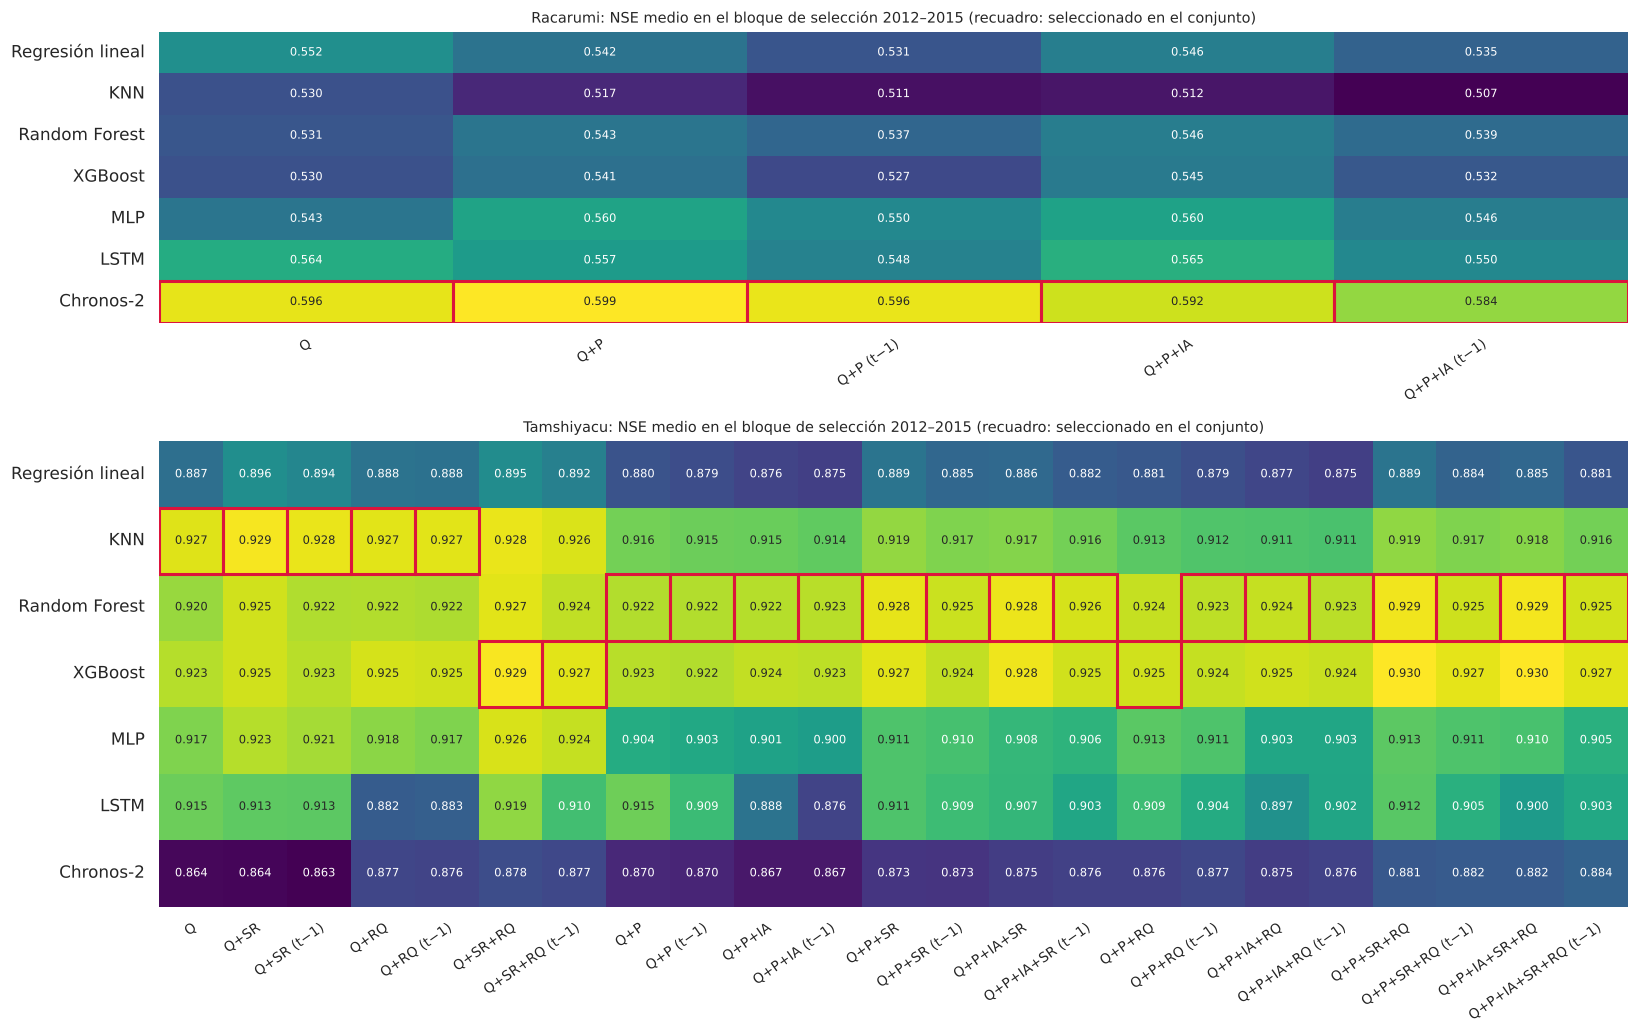

In [5]:
VAL, SELM, MV = [], {}, []
for e in EST:
    VAL.append(I.tabla_validacion(X[e], P[e], R=R[e]))
    SELM[e], mv = I.seleccion_por_conjunto(X[e], P[e], modelos=CAND_M, B=B)
    MV.append(mv)
val = pd.concat(VAL, ignore_index=True); metodo_val = pd.concat(MV, ignore_index=True)
val.to_csv(RUTA_TAB / 'tabla_validacion.csv', index=False)
metodo_val.to_csv(RUTA_TAB / 'tabla_seleccion_modelo_por_conjunto.csv', index=False)
fig, ax = plt.subplots(2, 1, figsize=(15, 9.5), gridspec_kw={'height_ratios': [1, 1.6]})
for a, e in zip(ax, EST):
    I.fig_validacion(a, X[e], val, SELM[e], CAND_M)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_validacion.png', dpi=200, bbox_inches='tight'); plt.show()

**Figura 1.** NSE medio de los 30 horizontes en el bloque de selección (2012–2015) de cada familia (filas) con cada combinación de entradas (columnas), en las mismas emisiones; el recuadro marca la familia elegida en cada combinación con la regla de selección del estudio.

In [6]:
filas, CONFIG, EQUIV, NOPEOR, SELS = [], {}, {}, {}, {}
for (e, alc), (ok, ip) in ALCANCES.items():
    for esc in I.ESCENARIOS:
        cand = [k for k in P[e] if ok(k[0]) and I.en_escenario(k[0], k[1], esc)]
        s_ = SELS[(e, alc, esc)] = I.seleccion_configuracion(X[e], P[e], cand, B=B)
        CONFIG[(e, alc, esc)], EQUIV[(e, alc, esc)], NOPEOR[(e, alc, esc)] = s_['elegida'], s_['equivalentes'], s_['no_peores']
        eq, inc = s_['equivalentes'], [k for k in s_['no_peores'] if k not in s_['equivalentes']]
        filas.append({'estación': e, 'periodo de prueba': alc, 'escenario': esc, **s_['resumen'],
                      'familias entre el mayor y sus equivalentes': ', '.join(n for n in CAND_M if any(k[2] == n for k in eq)),
                      'familias entre las inconclusas': ', '.join(n for n in CAND_M if any(k[2] == n for k in inc)) or '—',
                      'Chronos-2: clase': ('mayor o equivalente' if any(k[2] == CH for k in eq) else 'inconclusa' if any(k[2] == CH for k in inc) else 'peor')})
config = pd.DataFrame(filas).set_index(['estación', 'periodo de prueba', 'escenario'])
config.to_csv(RUTA_TAB / 'tabla_seleccion_magnitud_validacion.csv')
pd.set_option('display.max_colwidth', 120)
config.T

estación                                                                                                                                                                Racarumi  \
periodo de prueba                                                                                                                                       prueba 2016-01 a 2023-08   
escenario                                                                                                                                                              mismo día   
candidatos                                                                                                                                                                    21   
mayor NSE medio                                                                                                                                                  Q+P · Chronos-2   
NSE medio del mayor                                                                                                                                                      0.59895   
seleccionada (la más simple entre el mayor y sus equivalentes)                                                                                                     Q · Chronos-2   
NSE medio de la seleccionada                                                                                                                                            0.595678   
equivalentes al mayor (IC dentro de ±0.01)                                                                                                                                     1   
inconclusas (IC demasiado ancho; no es equivalencia)                                                                                                                           7   
peores (IC < 0)                                                                                                                                                               12   
no demostradas peores (mayor + equivalentes + inconclusas)                                                                                                                     9   
equivalentes: las 5 de mayor NSE medio                                                                                           Q+P · Chronos-2 (0.599) | Q · Chronos-2 (0.596)   
inconclusas: las 5 de mayor NSE medio                           Q+P+IA · Chronos-2 (0.592) | Q+P+IA · LSTM (0.565) | Q · LSTM (0.564) | Q+P · MLP (0.560) | Q+P+IA · MLP (0.560)   
familias entre el mayor y sus equivalentes                                                                                                                             Chronos-2   
familias entre las inconclusas                                                                                                                              MLP, LSTM, Chronos-2   
Chronos-2: clase                                                                                                                                             mayor o equivalente   

estación                                                                                                                                                                                 \
periodo de prueba                                                                                                                                                                         
escenario                                                                                                                                                             un día de retraso   
candidatos                                                                                                                                                                           21   
mayor NSE medio                                                                                                                                                   Q+P (t−1) · Chronos-2   
NSE 

In [7]:
# Coherencia con 05 y 06: la misma regla, con los mismos candidatos que esos cuadernos, debe elegir lo mismo
r06, r05 = PREVIAS['lluvia'], PREVIAS['aguas_arriba']
for esc in I.ESCENARIOS:
    cand = [k for k in P['Racarumi'] if k[2] != CH and I.en_escenario(k[0], k[1], esc)]
    s6 = I.nombre(I.seleccion_configuracion(xR, P['Racarumi'], cand, B=B)['elegida'])
    verificar('coherencia entre cuadernos', f'Racarumi, {esc}: la selección con los candidatos del 06 reproduce la del 06',
              s6 == r06['configuracion_seleccionada'][f'Racarumi|{esc}'], s6)
    for per, ok in [(ALC_SR, lambda c: RQ not in c), (ALC_RQ, lambda c: True)]:
        cand = [k for k in P['Tamshiyacu'] if k[2] != CH and cuaderno('Tamshiyacu', k[0], k[1]) == '05' and ok(k[0]) and I.en_escenario(k[0], k[1], esc)]
        s5 = I.nombre(I.seleccion_configuracion(xT, P['Tamshiyacu'], cand, B=B)['elegida'])
        verificar('coherencia entre cuadernos', f'Tamshiyacu {per}, {esc}: la selección con los candidatos del 05 reproduce la del 05',
                  s5 == r05['configuracion_seleccionada'][f'{per}|{esc}'], s5)
pd.DataFrame(VERIF).query("grupo == 'coherencia entre cuadernos'").set_index('comprobación')[['resultado', 'detalle']]

,resultado,detalle
comprobación,,
"Racarumi, mismo día: la selección con los candidatos del 06 reproduce la del 06",correcto,Q+P+IA · LSTM
"Tamshiyacu con San Regis (prueba 2016-01 a 2025-12), mismo día: la selección con los candidatos del 05 reproduce la del 05",correcto,Q · KNN
"Tamshiyacu común con Requena (prueba 2016-01 a 2020-03), mismo día: la selección con los candidatos del 05 reproduce la del 05",correcto,Q+SR · KNN
"Racarumi, un día de retraso: la selección con los candidatos del 06 reproduce la del 06",correcto,Q · LSTM
"Tamshiyacu con San Regis (prueba 2016-01 a 2025-12), un día de retraso: la selección con los candidatos del 05 reproduce la del 05",correcto,Q · KNN
"Tamshiyacu común con Requena (prueba 2016-01 a 2020-03), un día de retraso: la selección con los candidatos del 05 reproduce la del 05",correcto,Q · KNN


**Interpretación (validación, bloque 2012–2015):**
- **Cómo leer las clases.** Frente al candidato de mayor NSE medio, un candidato es **equivalente** si el IC 90 % de la diferencia cabe en ±0.01 (diferencia demostrada pequeña: la regla puede elegirlo por simple), **inconcluso** si el IC es demasiado ancho para decir que es equivalente, mejor o peor (falta evidencia; **no es equivalencia** y la regla no lo elige) y **peor** si el IC queda por debajo de 0. Las dos clases se informan por separado.
- **Racarumi: Chronos-2 tiene el mayor NSE medio de selección con cada combinación de entradas** (0.584–0.599, frente a 0.550–0.565 de la LSTM, la mejor de las familias entrenadas). La regla elige **Q · Chronos-2 en los dos escenarios**: Q+P · Chronos-2 es el mayor (0.599) y Q · Chronos-2 (0.596) es su único equivalente y es más simple. Otros 7 de los 21 candidatos quedan **inconclusos** (MLP, LSTM y Chronos-2 con índices): la validación no basta para ordenarlos, pero tampoco muestra que sean equivalentes.
- **Tamshiyacu: Chronos-2 queda por debajo de las familias entrenadas** (0.863–0.884 frente a 0.922–0.930 del mejor modelo entrenado de cada combinación). Con San Regis (42 candidatos), el mayor es Q+SR · KNN (0.929) y la regla elige **Q · KNN** en los dos escenarios; Q · KNN está entre los 6 equivalentes (con retraso, 4), junto con combinaciones con lluvia y San Regis de Random Forest y XGBoost (por ejemplo, Q+P+IA+SR · XGBoost, 0.928); 10–11 quedan inconclusos. **En el periodo común con Requena (84 candidatos, con las 12 combinaciones)** el mayor es **Q+P+SR+RQ · XGBoost (0.930)**, una de las combinaciones de lluvia con Requena, pero 12 candidatos son equivalentes y la regla elige el más simple, **Q+SR · KNN** (0.929), si las fuentes llegan el mismo día; con un día de retraso elige **Q · KNN** (12 equivalentes y 20 inconclusos). **Agregar la lluvia y los índices con Requena no cambia ninguna selección**: sus mejores versiones son equivalentes a otras más simples.
- **Coherencia:** con los mismos candidatos que 05 y 06 (sin Chronos-2 ni las combinaciones con lluvia y caudal aguas arriba), la regla reproduce exactamente sus selecciones (registro de verificaciones). Lo que cambia en Racarumi es la presencia de Chronos-2.
- **Lectura:** el NSE medio de 30 horizontes con margen ±0.01 es una regla fijada antes de ejecutar. Premia la simplicidad cuando las diferencias son demostradamente pequeñas y no premia ganancias concentradas en la primera semana; los inconclusos indican dónde la validación no tiene información suficiente.

---
## 5. Prueba: la selección para la magnitud, sin cambiarla
En cada periodo de prueba, todos los candidatos en las **mismas emisiones**: NSE por horizonte, NSE medio y horizonte útil (cota 95 %). Para cada selección: su desempeño, la diferencia con **solo caudal** (Q con la familia elegida en validación para Q) y con cada otro candidato del mismo escenario (ΔNSE medio con IC 90 % por bootstrap pareado de meses), el **mejor observado en la prueba** (que no se usa para elegir) y si la prueba lo distingue del seleccionado.

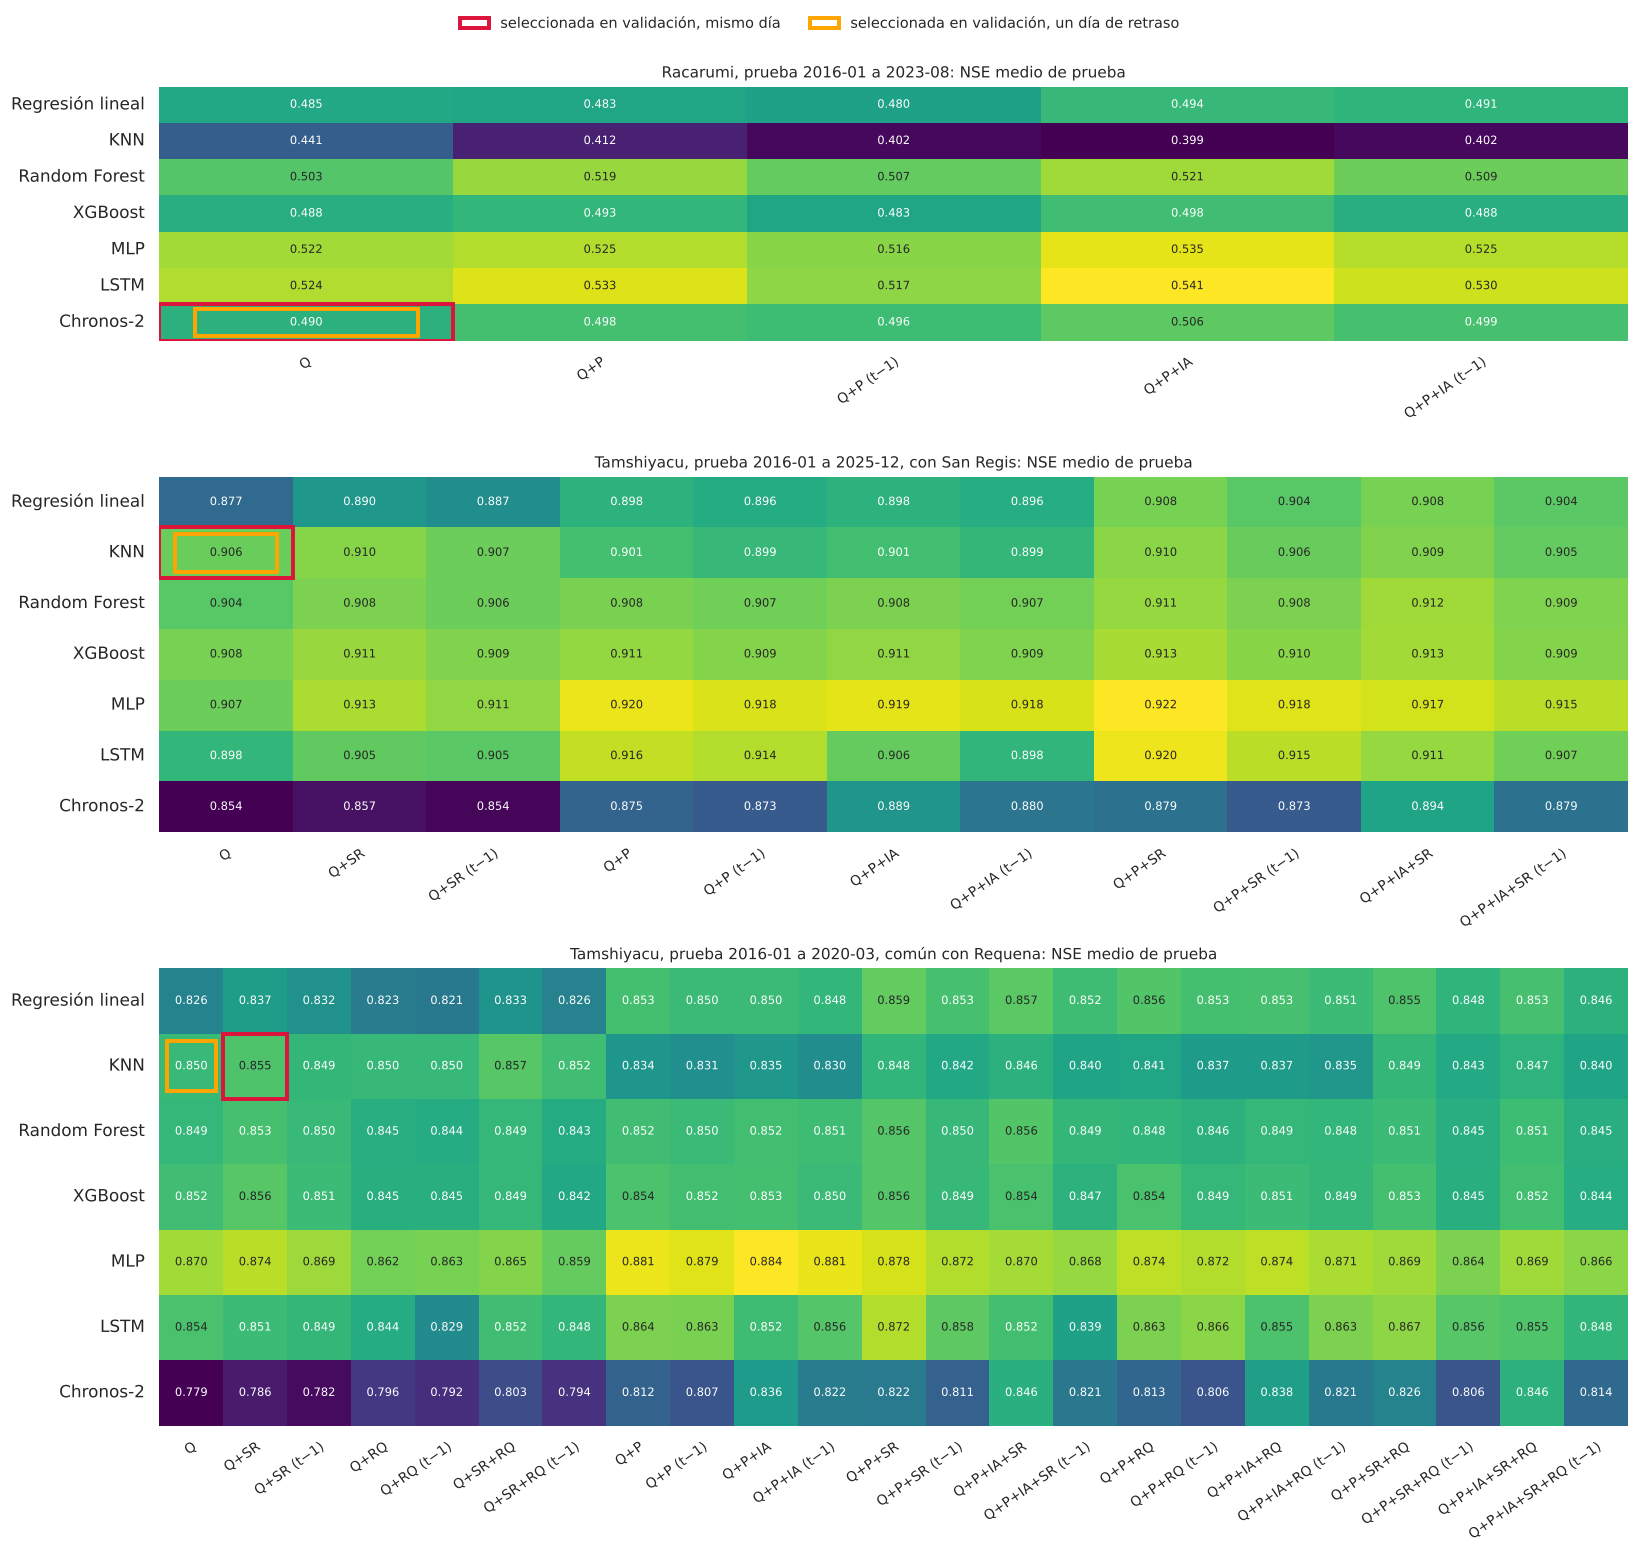

In [8]:
PR, HZ, TABH = [], {}, {}
for (e, alc), (ok, ip) in ALCANCES.items():
    claves = [k for k in P[e] if ok(k[0]) and (k[0], k[1]) not in EN.CONJUNTOS_CONTROL]
    t_, HZ[(e, alc)], TABH[(e, alc)] = I.metricas_prueba(X[e], P[e], claves, ip=ip, B=B)
    PR += [t_.assign(**{'periodo de prueba': alc}), I.referencias_prueba(X[e], ip).assign(**{'periodo de prueba': alc})]
prueba = pd.concat(PR, ignore_index=True)
prueba.to_csv(RUTA_TAB / 'tabla_metricas_prueba.csv', index=False)
pmod = prueba[prueba['modelo'].isin(CAND_M)]
from matplotlib.patches import Patch
# título de cada panel: periodo de prueba primero y, si aplica, el conjunto de estaciones que lo define
titulo_periodo = lambda alc: alc if alc.startswith('prueba') else f"{alc[alc.index('(') + 1:-1]}, {alc[:alc.index(' (')]}"
fig, ax = plt.subplots(3, 1, figsize=(15, 14), gridspec_kw={'height_ratios': [1, 1.4, 1.8]})
for a, ((e, alc), _) in zip(ax, ALCANCES.items()):
    t = pmod[(pmod['estación'] == e) & (pmod['periodo de prueba'] == alc)].pivot_table(index='conjunto', columns='modelo', values='NSE medio', sort=False)[CAND_M]
    sns.heatmap(t.T, annot=True, fmt='.3f', cmap='viridis', ax=a, cbar=False, annot_kws={'fontsize': 7.5})
    # recuadro rojo exterior (mismo día) y naranja interior (un día de retraso): ambos quedan visibles si coinciden
    for esc, mk, d in zip(I.ESCENARIOS, ['crimson', 'orange'], [0.0, 0.12]):
        c, l, n = CONFIG[(e, alc, esc)]
        a.add_patch(plt.Rectangle((list(t.index).index(I.etiqueta(c, l)) + d, CAND_M.index(n) + d), 1 - 2 * d, 1 - 2 * d, fill=False, ec=mk, lw=2.6))
    a.set_title(f'{e}, {titulo_periodo(alc)}: NSE medio de prueba', fontsize=10)
    a.set_xlabel(''); a.set_ylabel('')
    plt.setp(a.get_xticklabels(), rotation=35, ha='right', rotation_mode='anchor', fontsize=9)
fig.legend(handles=[Patch(fill=False, ec='crimson', lw=2.6, label='seleccionada en validación, mismo día'),
                    Patch(fill=False, ec='orange', lw=2.6, label='seleccionada en validación, un día de retraso')],
           loc='upper center', ncol=2, fontsize=9.5, frameon=False, bbox_to_anchor=(0.5, 1.01))
fig.tight_layout(rect=(0, 0, 1, 0.98)); fig.savefig(RUTA_FIG / 'fig02_prueba_nse_medio.png', dpi=200, bbox_inches='tight'); plt.show()


**Figura 2.** NSE medio de prueba de cada candidato en su periodo (las mismas emisiones para todos los de un panel). El recuadro rojo (exterior) marca la configuración seleccionada en validación para el escenario de mismo día y el naranja (interior), la del escenario con un día de retraso; cuando ambos escenarios eligen la misma, aparecen los dos en la misma celda. La prueba no interviene en la selección, por lo que la seleccionada no tiene por qué ser la de mayor NSE en la prueba. La escala de color es propia de cada panel.

In [9]:
FINAL_M, COMP_T = [], []
for (e, alc), (ok, ip) in ALCANCES.items():
    x, tb = X[e], pmod[(pmod['estación'] == e) & (pmod['periodo de prueba'] == alc)].set_index(['conjunto', 'modelo'])
    for esc in I.ESCENARIOS:
        k = CONFIG[(e, alc, esc)]
        cand = [kk for kk in P[e] if ok(kk[0]) and I.en_escenario(kk[0], kk[1], esc)]
        ct = I.comparar_con(x, P[e], k, cand, B=B, ip=ip).assign(**{'periodo de prueba': alc, 'escenario': esc})
        COMP_T.append(ct)
        base = ('Q', 0, SELM[e][('Q', 0)])
        cq = I.comparar_con(x, P[e], base, [k], B=B, ip=ip).iloc[0] if k != base else None
        r_ = tb.loc[(I.etiqueta(k[0], k[1]), k[2])]
        mej = tb.loc[[(I.etiqueta(c, l), n) for c, l, n in cand]]['NSE medio'].idxmax()
        km = next(kk for kk in cand if (I.etiqueta(kk[0], kk[1]), kk[2]) == mej)
        dm = ct[ct['configuración'] == I.nombre(km)]
        FINAL_M.append({'estación': e, 'periodo de prueba': alc, 'escenario': esc, 'objetivo': 'magnitud del caudal',
                        'seleccionada en validación': I.nombre(k), 'disponibilidad supuesta': I.disponibilidad(k[0], k[1]),
                        'NSE medio validación (2012–2015)': config.loc[(e, alc, esc), 'NSE medio de la seleccionada'],
                        'equivalentes al mayor en validación (incluido el mayor)': len(EQUIV[(e, alc, esc)]),
                        'inconclusos en validación': len(NOPEOR[(e, alc, esc)]) - len(EQUIV[(e, alc, esc)]), 'candidatos': len(cand),
                        'NSE medio prueba': r_['NSE medio'], 'NSE h=1': r_['NSE h=1'], 'NSE h=7': r_['NSE h=7'], 'NSE h=30': r_['NSE h=30'],
                        'H cota 95 % (d)': int(r_['H cota 95 % (d)']), 'H p05–p95 de las réplicas (d)': r_['H p05–p95 de las réplicas (d)'],
                        'solo caudal (referencia)': I.nombre(base),
                        'ΔNSE medio frente a solo caudal (IC 90 %)': '— (es la misma)' if cq is None else f"{cq['ΔNSE medio']:+.3f} [{cq['IC90 inferior']:+.3f}, {cq['IC90 superior']:+.3f}] {I.CLASE.get(cq['clase'], '')}",
                        'G 1–3 d frente a solo caudal': np.nan if cq is None else cq[f'G {I.BANDAS[0]}'],
                        'mejor NSE medio en la prueba (no se elige con él)': f"{I.nombre(km)} ({tb.loc[mej, 'NSE medio']:.3f})",
                        'el mejor en prueba coincide con el seleccionado': km == k,
                        'mejor en prueba frente al seleccionado': '—' if km == k else f"{dm['ΔNSE medio'].iloc[0]:+.3f} [{dm['IC90 inferior'].iloc[0]:+.3f}, {dm['IC90 superior'].iloc[0]:+.3f}] {dm['clase'].iloc[0]}",
                        'en la prueba frente al seleccionado: mejores (IC > 0)': int((ct['clase'] == 'mejora').sum()),
                        'equivalentes (IC dentro de ±0.01)': int((ct['clase'] == 'equivalente').sum()),
                        'inconclusos (IC ancho)': int((ct['clase'] == 'inconcluso').sum()),
                        'peores (IC < 0)': int((ct['clase'] == 'peor').sum()),
                        'cumple: H cota 95 % ≥ 1 día': int(r_['H cota 95 % (d)']) >= 1})
final_m = pd.DataFrame(FINAL_M).set_index(['estación', 'periodo de prueba', 'escenario'])
comp_t = pd.concat(COMP_T, ignore_index=True)
comp_t.to_csv(RUTA_TAB / 'tabla_prueba_frente_a_seleccionada.csv', index=False)
final_m.to_csv(RUTA_TAB / 'tabla_seleccion_magnitud_prueba.csv')
final_m.drop(columns=['objetivo']).T

estación                                                                       Racarumi  \
periodo de prueba                                              prueba 2016-01 a 2023-08   
escenario                                                                     mismo día   
seleccionada en validación                                                Q · Chronos-2   
disponibilidad supuesta                                     solo caudal local (hasta t)   
NSE medio validación (2012–2015)                                               0.595678   
equivalentes al mayor en validación (incluido el mayor)                               2   
inconclusos en validación                                                             7   
candidatos                                                                           21   
NSE medio prueba                                                               0.490092   
NSE h=1                                                                        0.855605   
NSE h=7                                                                         0.49516   
NSE h=30                                                                       0.435636   
H cota 95 % (d)                                                                       5   
H p05–p95 de las réplicas (d)                                                      5–19   
solo caudal (referencia)                                                  Q · Chronos-2   
ΔNSE medio frente a solo caudal (IC 90 %)                               — (es la misma)   
G 1–3 d frente a solo caudal                                                        NaN   
mejor NSE medio en la prueba (no se elige con él)                 Q+P+IA · LSTM (0.541)   
el mejor en prueba coincide con el seleccionado                                   False   
mejor en prueba frente al seleccionado                   +0.051 [+0.019, +0.080] mejora   
en la prueba frente al seleccionado: mejores (IC > 0)                                10   
equivalentes (IC dentro de ±0.01)                                                     0   
inconclusos (IC ancho)                                                                7   
peores (IC < 0)                                                                       3   
cumple: H cota 95 % ≥ 1 día                                                        True   

estación                                                                                 \
periodo de prueba                                                                         
escenario                                                             un día de retraso   
seleccionada en validación                                                Q · Chronos-2   
disponibilidad supuesta                                     solo caudal local (hasta t)   
NSE medio validación (2012–2015)                                               0.595678   
equivalentes al mayor en validación (incluido el mayor)                               2   
inconclusos en validación                                                             7   
candidatos                                                                           21   
NSE medio prueba                                                               0.490092   
NSE h=1                                                                        0.855605   
NSE h=7                                                                         0.49516   
NSE h=30                                                                       0.435636   
H cota 95 % (d)                                                                       5   
H p05–p95 de las réplicas (d)                                                      5–19   
solo caudal (referencia)                                                  Q · Chronos-2   
ΔNSE medio frente a solo caudal (IC 90 %)                               — (es la misma)   
G 1–3 d frente a solo caudal                                                        Na

**Interpretación (prueba, sin cambiar la selección):**
- **Racarumi: lo elegido en validación no se sostiene en la prueba.** Q · Chronos-2 logra NSE medio 0.490 y horizonte útil de 5 días (cota 95 %), mientras **10 de los otros 20 candidatos del escenario «mismo día» son mejores con IC 90 % > 0** (7 inconclusos, 3 peores, ninguno equivalente): el mayor de la prueba es Q+P+IA · LSTM (0.541; +0.051, IC +0.019 a +0.080) y también Q · LSTM (+0.034). Con un día de retraso, 6 son mejores (el mayor, Q+P+IA (t−1) · LSTM, +0.040). La ventaja de Chronos-2 en 2012–2015 (+0.03 sobre la LSTM) se invirtió en 2016–2023: su contexto y su pronóstico puntual se eligieron en ese mismo bloque, y la prueba incluye el Niño costero de 2017. **Con esta regla y esta validación, la selección para la magnitud en Racarumi no es confiable**; se informa así y no se corrige con la prueba.
- **Tamshiyacu con San Regis:** Q · KNN logra NSE medio 0.906 y horizonte útil ≥ 30 días. El mayor de la prueba es **Q+P+SR · MLP (0.922; +0.016, IC +0.006 a +0.025)**; frente a la seleccionada, 8 candidatos son mejores con IC > 0, 10 equivalentes, 15 inconclusos y 8 peores (con un día de retraso: 3, 15, 11 y 12). La diferencia es pequeña frente al nivel ya alto, pero muestra que San Regis y la lluvia juntos sí mejoran la magnitud en la prueba aunque la validación no lo distinguía.
- **Tamshiyacu en el periodo con Requena:** Q+SR · KNN (mismo día) da 0.855 y 18 días; frente a Q · KNN, ΔNSE medio +0.005 (inconcluso) pero **28 % menos error a 1–3 días**. Con retraso, Q · KNN: 0.850 y 17 días. El mayor de la prueba es Q+P+IA · MLP (0.884; +0.029 frente a la seleccionada, IC > 0); las combinaciones de lluvia con Requena no lo superan (la mejor, Q+P+RQ · MLP, 0.874). Frente a la seleccionada, 5 candidatos son mejores, 2 equivalentes, 60 inconclusos (1 093 emisiones y un periodo corto dan IC anchos) y 16 peores.
- **Criterio de utilidad para la magnitud (H cota 95 % ≥ 1 día):** lo cumplen las seis selecciones; ninguna es la mejor observada en la prueba. **Chronos-2 es peor** que la seleccionada en 34 de las 36 comparaciones de Tamshiyacu (−0.009 a −0.076 de NSE medio; las otras 2, inconclusas); en Racarumi, con lluvia y con lluvia e índices mejora a su propia versión con Q (+0.008 y +0.016).

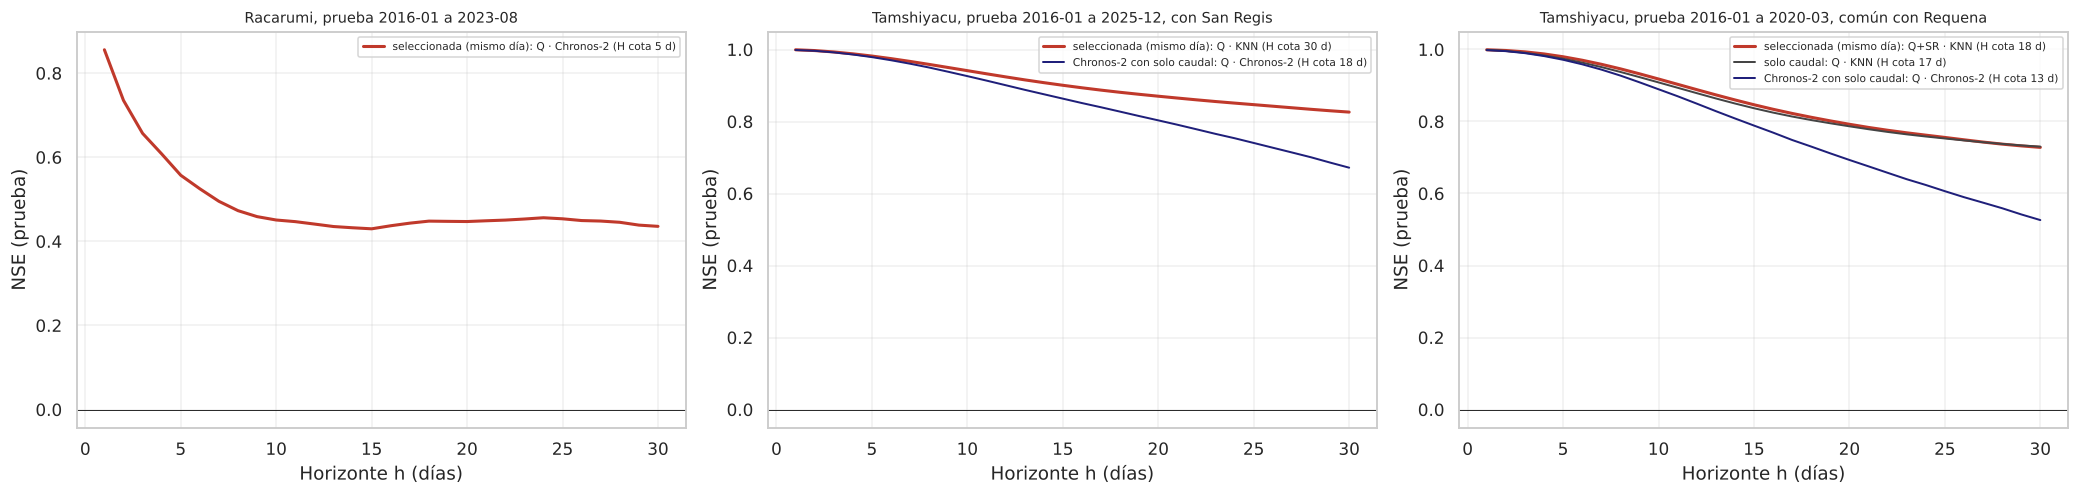

In [10]:
hh = np.array(C.HORIZONTES)
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6), sharey=False)
for a, ((e, alc), _) in zip(ax, ALCANCES.items()):
    TB, HZ_ = TABH[(e, alc)], HZ[(e, alc)]
    vistas = set()
    for esc, ls in zip(I.ESCENARIOS, ['-', '--']):
        k = CONFIG[(e, alc, esc)]
        for kk, col, et in [(k, '#c0392b' if esc == 'mismo día' else '#e67e22', f'seleccionada ({esc})'), (('Q', 0, SELM[e][('Q', 0)]), '#444444', 'solo caudal'),
                            (('Q', 0, CH), I.COLOR[CH], 'Chronos-2 con solo caudal')]:
            if kk in vistas:
                continue
            vistas.add(kk)
            a.plot(hh, TB[kk]['NSE'], color=col, ls=ls if kk == k else '-', lw=2 if kk == k else 1.3, label=f"{et}: {I.nombre(kk)} (H cota {HZ_[kk]['H_cota']} d)")
    a.axhline(0, color='k', lw=0.6); a.grid(True, alpha=0.3); a.set_xlabel('Horizonte h (días)'); a.set_ylabel('NSE (prueba)')
    a.set_title(f'{e}, {titulo_periodo(alc)}', fontsize=9.5); a.legend(fontsize=7)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig03_seleccionadas_nse_horizonte.png', dpi=200, bbox_inches='tight'); plt.show()

**Figura 3.** NSE por horizonte en la prueba de las configuraciones seleccionadas en validación para la magnitud (continua: mismo día; discontinua: un día de retraso), frente a solo caudal con la familia elegida para Q y a Chronos-2 con solo caudal; en la leyenda, la cota 95 % del horizonte útil.

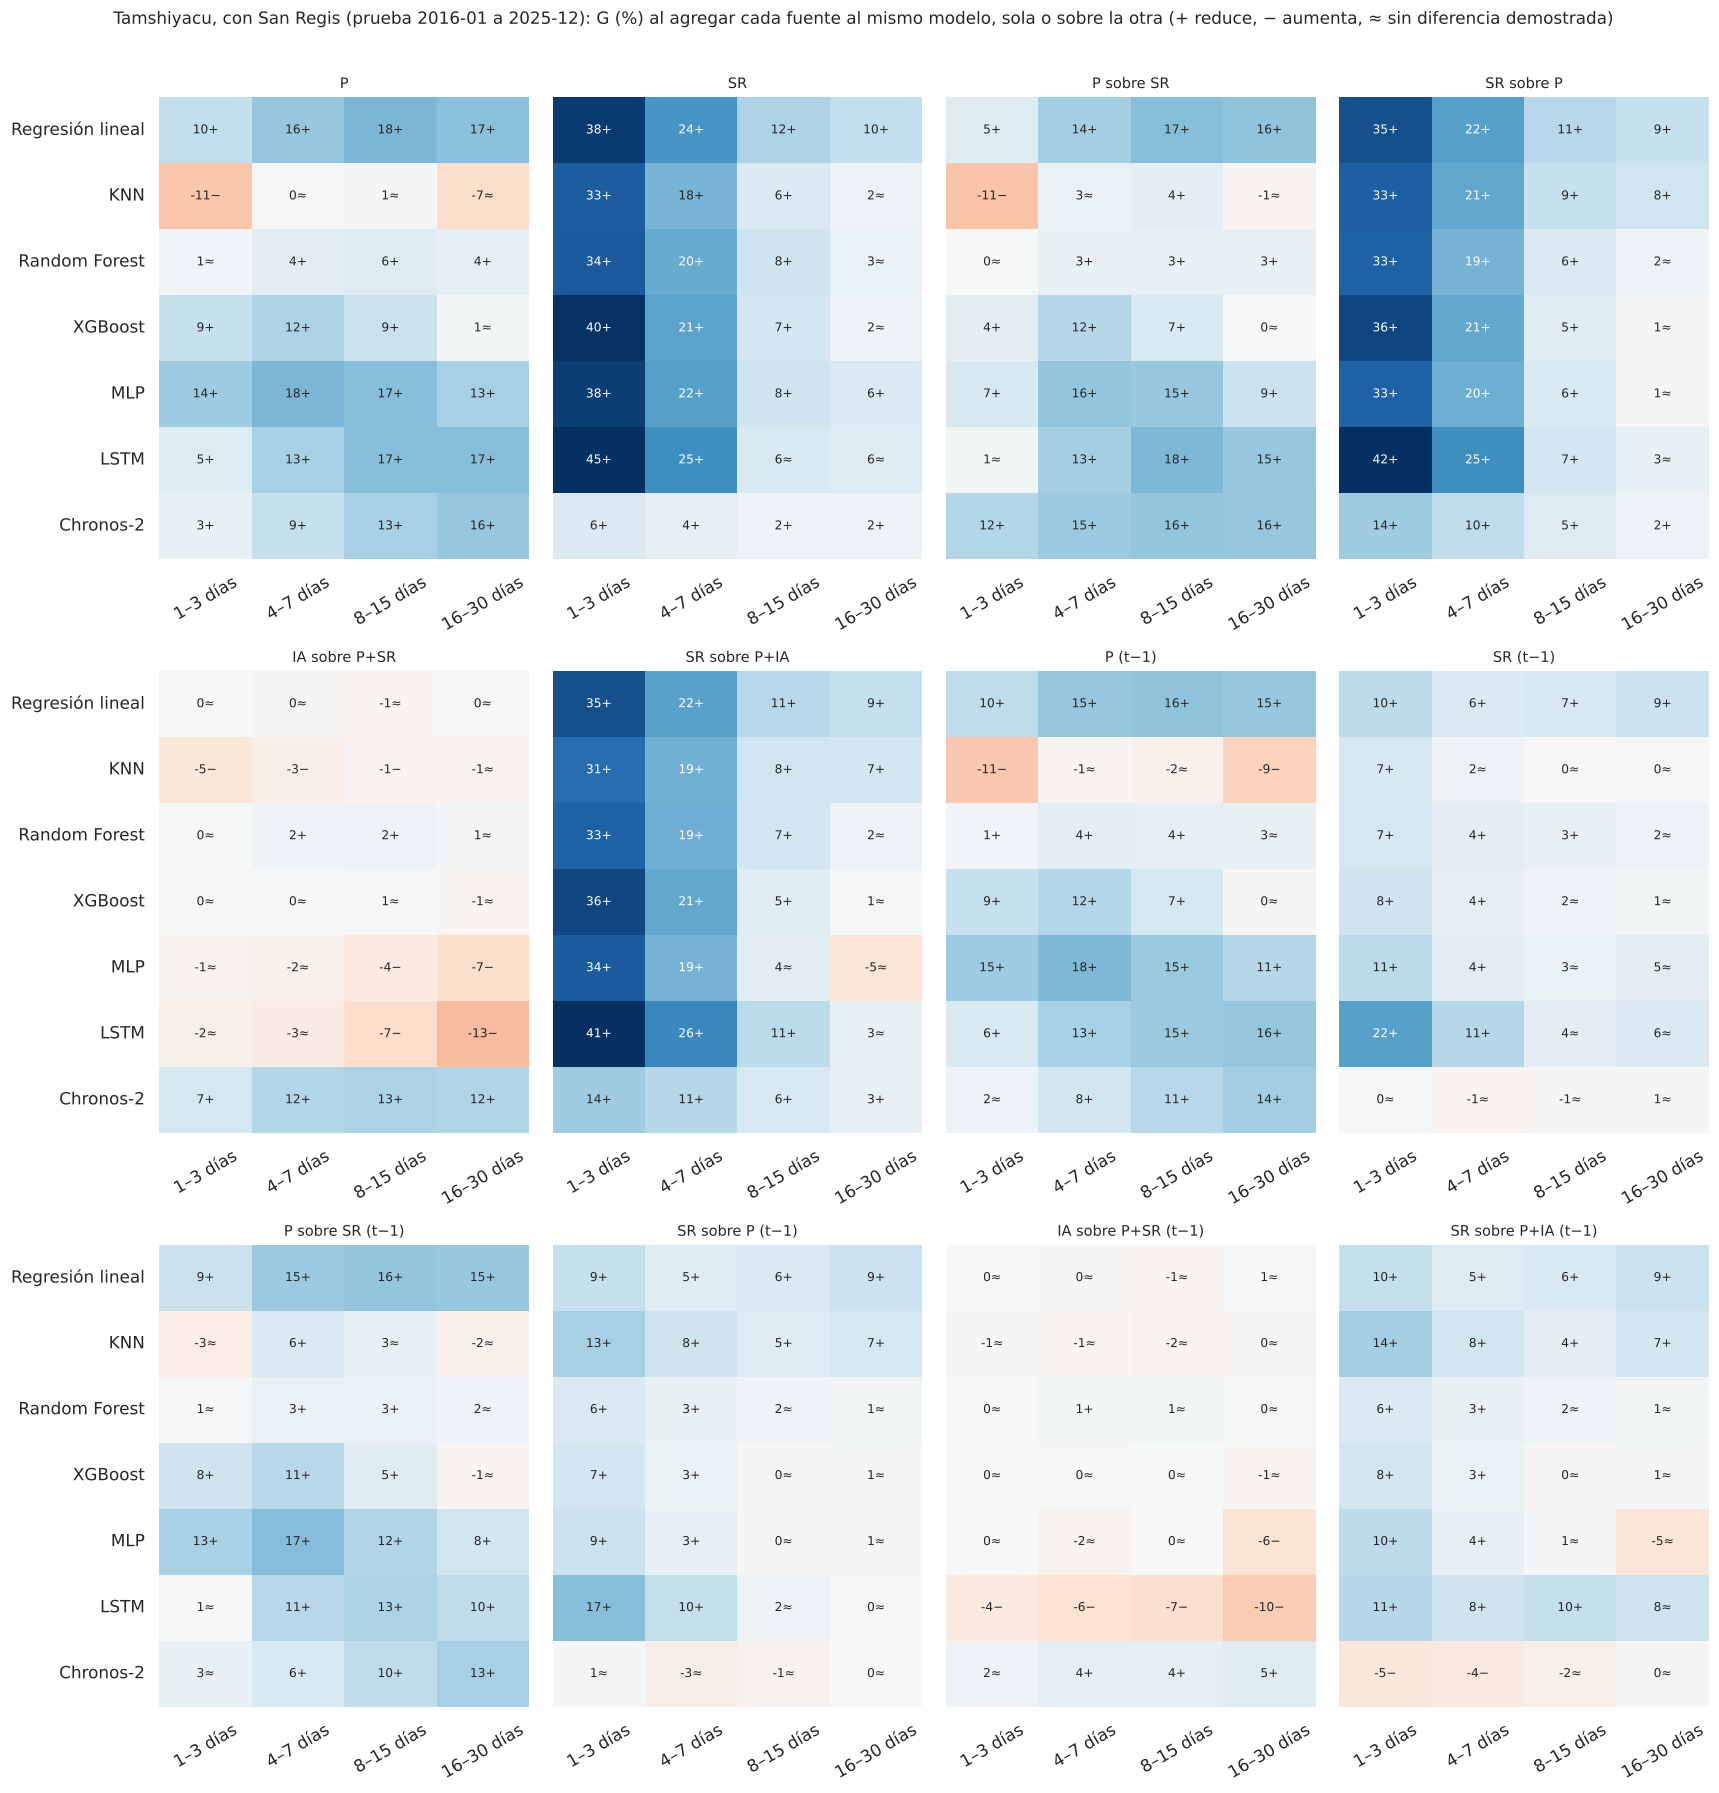

modelo,Regresión lineal,KNN,Random Forest,XGBoost,MLP,LSTM,Chronos-2
entrada,,,,,,,
P,-0.007 ?,-0.011 ▼,+0.003 =,+0.000 =,-0.013 ▼,+0.000 =,+0.006 ?
SR,+0.008 ▲,+0.002 =,+0.005 ?,+0.002 =,+0.006 ▲,-0.002 ?,-0.000 =
P sobre SR,-0.007 ?,-0.010 ▼,+0.003 ▲,+0.002 =,-0.011 ▼,-0.002 ?,+0.009 ▲
SR sobre P,+0.009 ▲,+0.003 =,+0.005 ▲,+0.004 ▲,+0.007 ▲,-0.004 ?,+0.003 =
IA sobre P+SR,-0.003 =,-0.002 =,+0.000 =,+0.001 ▲,-0.004 =,-0.004 ?,+0.002 =
SR sobre P+IA,+0.009 ▲,+0.003 =,+0.006 ▲,+0.004 ▲,+0.006 ▲,+0.019 ▲,+0.008 ?
P (t−1),-0.009 ?,-0.012 ▼,+0.002 =,-0.000 =,-0.014 ▼,-0.006 ?,+0.006 ?
SR (t−1),+0.006 ?,+0.001 =,+0.002 =,+0.000 =,+0.004 =,-0.002 ?,-0.001 =
P sobre SR (t−1),-0.009 ?,-0.011 ▼,+0.003 =,+0.001 =,-0.011 ▼,-0.004 ?,+0.010 ▲


modelo,Regresión lineal,KNN,Random Forest,XGBoost,MLP,LSTM,Chronos-2
entrada,,,,,,,
P,+10 % +,-11 % −,+1 % ≈,+9 % +,+14 % +,+5 % +,+3 % +
SR,+38 % +,+33 % +,+34 % +,+40 % +,+38 % +,+45 % +,+6 % +
P sobre SR,+5 % +,-11 % −,+0 % ≈,+4 % +,+7 % +,+1 % ≈,+12 % +
SR sobre P,+35 % +,+33 % +,+33 % +,+36 % +,+33 % +,+42 % +,+14 % +
IA sobre P+SR,+0 % ≈,-5 % −,+0 % ≈,+0 % ≈,-1 % ≈,-2 % ≈,+7 % +
SR sobre P+IA,+35 % +,+31 % +,+33 % +,+36 % +,+34 % +,+41 % +,+14 % +
P (t−1),+10 % +,-11 % −,+1 % +,+9 % +,+15 % +,+6 % +,+2 % ≈
SR (t−1),+10 % +,+7 % +,+7 % +,+8 % +,+11 % +,+22 % +,+0 % ≈
P sobre SR (t−1),+9 % +,-3 % ≈,+1 % ≈,+8 % +,+13 % +,+1 % ≈,+3 % ≈


In [11]:
# Cuánto aporta combinar fuentes en Tamshiyacu (mismo modelo, mismas emisiones): lluvia y San Regis, solas y juntas
P_, SR_ = 'Q+P', 'Q+' + SR
COMP_TAM = []
for l, suf in [(0, ''), (1, ' (t−1)')]:
    COMP_TAM += [('P' + suf, ('Q+P', l), ('Q', 0)), ('SR' + suf, (SR_, l), ('Q', 0)), ('P sobre SR' + suf, (f'Q+P+{SR}', l), (SR_, l)),
                 ('SR sobre P' + suf, (f'Q+P+{SR}', l), ('Q+P', l)), ('IA sobre P+SR' + suf, (f'Q+P+IA+{SR}', l), (f'Q+P+{SR}', l)),
                 ('SR sobre P+IA' + suf, (f'Q+P+IA+{SR}', l), ('Q+P+IA', l))]
ev_t, evb_t = I.efecto_entrada_validacion(xT, P['Tamshiyacu'], COMP_TAM, CAND_M, B=B)
ep_t = I.efecto_entrada_prueba(xT, P['Tamshiyacu'], COMP_TAM, CAND_M, B=B)
ev_t.to_csv(RUTA_TAB / 'tabla_tamshiyacu_combinaciones_validacion.csv', index=False)
ep_t.to_csv(RUTA_TAB / 'tabla_tamshiyacu_combinaciones_prueba.csv', index=False)
I.fig_ganancias(ep_t, 'Tamshiyacu', [c[0] for c in COMP_TAM], RUTA_FIG / 'fig04_tamshiyacu_combinaciones.png',
                f'Tamshiyacu, {ALC_SR}: G (%) al agregar cada fuente al mismo modelo, sola o sobre la otra (+ reduce, − aumenta, ≈ sin diferencia demostrada)', CAND_M)
plt.show()
display(I.tabla_corta(ev_t, ['entrada'], None, I.fmt_delta, CAND_M))
I.tabla_corta(ep_t[ep_t['banda'] == I.BANDAS[0]], ['entrada'], None, I.fmt_g, CAND_M)

**Figura 4.** Tamshiyacu, con San Regis (prueba 2016-01 a 2025-12): G (%) de cada fuente con la misma familia, por banda de horizonte: la lluvia y San Regis solas, cada una sobre la otra y los índices antecedentes sobre ambas, con las fuentes hasta t (fila superior) y hasta t−1 (inferior). Las tablas muestran el ΔNSE medio en validación y G a 1–3 días en la prueba.

**Interpretación (Tamshiyacu, con San Regis (prueba 2016-01 a 2025-12), misma familia y mismas emisiones):**
- **San Regis aporta lo mismo con y sin lluvia:** reduce el error 33–45 % a 1–3 días con las seis familias entrenadas (31–42 % sobre la lluvia, o sobre la lluvia y los índices) y 18–26 % a 4–7 días; a Chronos-2, solo 6 % (14 % sobre la lluvia).
- **La lluvia aporta en otros horizontes:** sobre San Regis reduce el error 7–18 % a 4–15 días con la regresión lineal, XGBoost, el MLP y la LSTM (y 9–16 % a 16–30 días con la lineal, el MLP y la LSTM; 12–16 % en todas las bandas con Chronos-2), y lo aumenta con el KNN a 1–3 días. **Las dos fuentes se complementan**: San Regis la primera semana; la lluvia, la segunda a cuarta.
- **Los índices antecedentes sobre lluvia y San Regis no dan una mejora consistente** con los modelos entrenados (la LSTM y el MLP empeoran a 8–30 días); a Chronos-2 sí lo ayudan (7–13 %).
- **Con un día de retraso:** San Regis conserva 6–22 % a 1–3 días con las familias entrenadas (nada con Chronos-2); la lluvia conserva casi todo su efecto (la cuenca responde en 6–7 días).
- **Validación frente a prueba:** en validación la lluvia sola es inconclusa o peor (KNN y MLP) en el NSE medio, y San Regis sobre la lluvia mejora con cuatro familias; la ganancia de la lluvia a 4–30 días se ve en la prueba, no en la validación. Por eso la regla no la adopta.

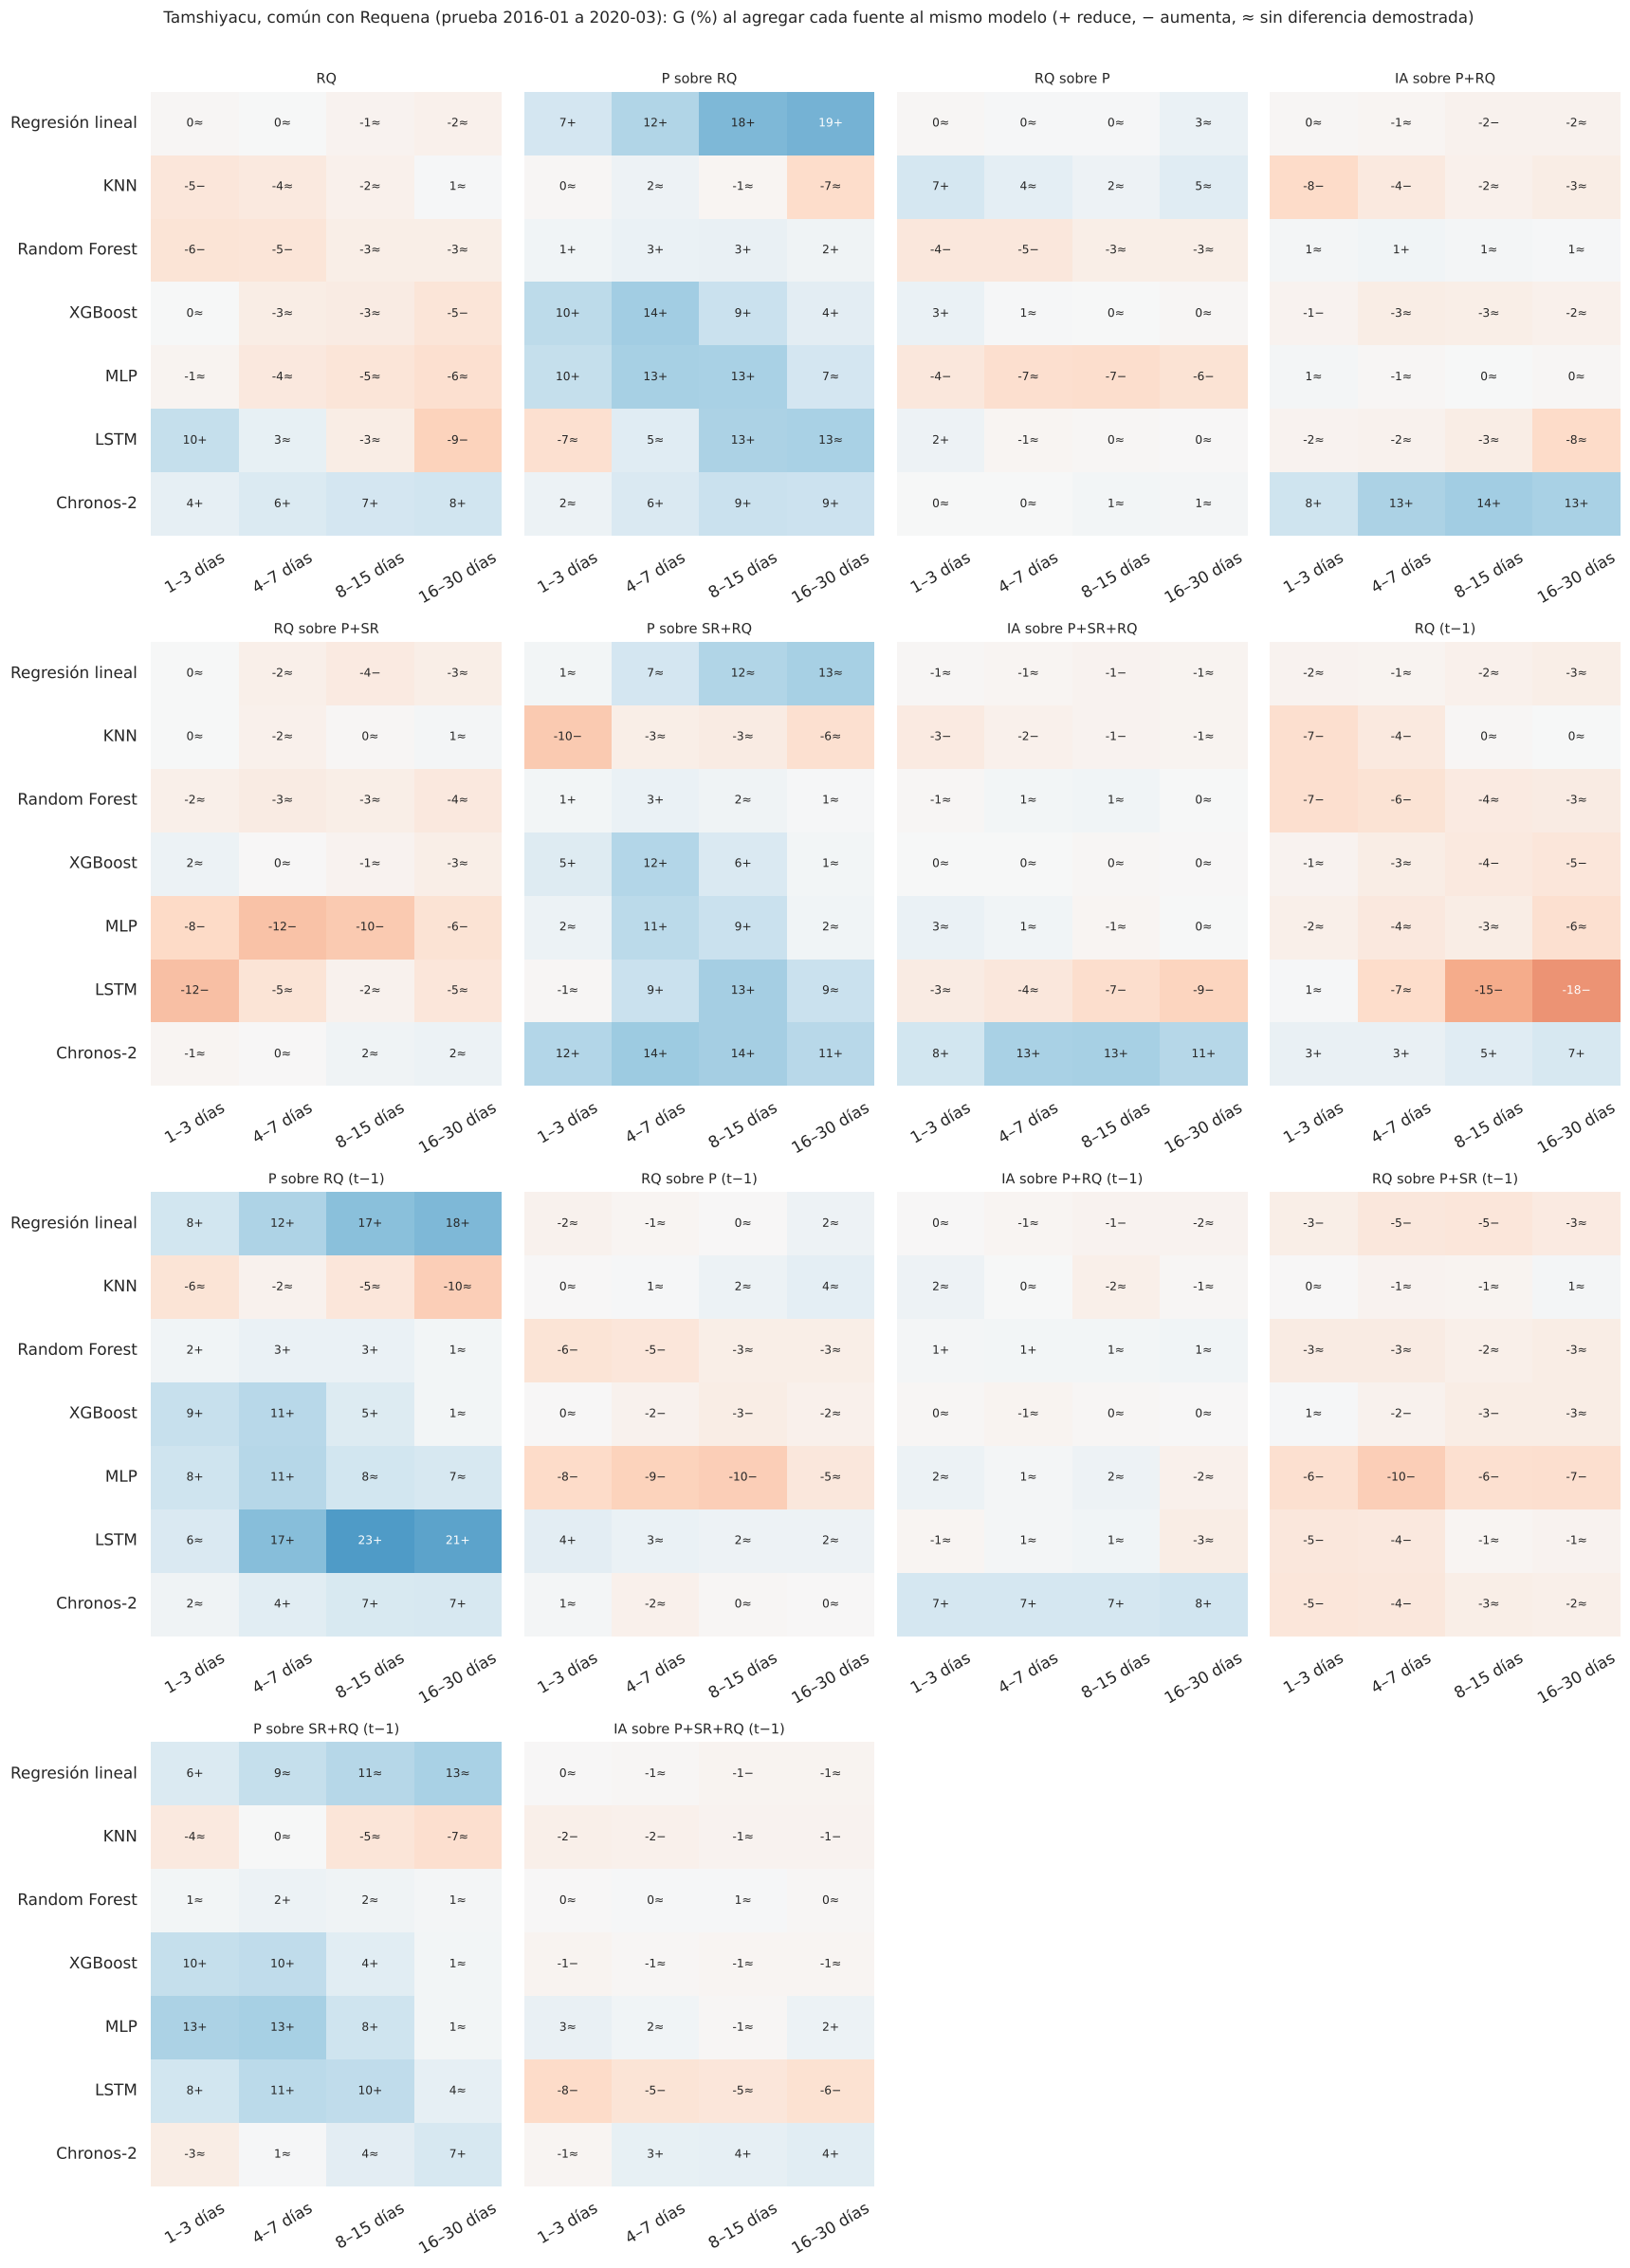

modelo,Regresión lineal,KNN,Random Forest,XGBoost,MLP,LSTM,Chronos-2
entrada,,,,,,,
RQ,+0.001 =,+0.000 =,+0.003 =,+0.003 =,+0.001 =,-0.033 ▼,+0.013 ▲
P sobre RQ,-0.007 ?,-0.014 ▼,+0.002 =,-0.000 =,-0.005 ?,+0.027 ?,-0.001 =
RQ sobre P,+0.001 =,-0.003 =,+0.002 =,+0.002 ▲,+0.009 ▲,-0.006 =,+0.006 ▲
IA sobre P+RQ,-0.004 ?,-0.002 =,+0.000 =,+0.000 =,-0.010 ▼,-0.012 ?,-0.001 =
RQ sobre P+SR,-0.000 =,-0.000 =,+0.001 =,+0.003 ▲,+0.002 =,+0.001 =,+0.008 ▲
P sobre SR+RQ,-0.007 ?,-0.009 ▼,+0.002 =,+0.001 =,-0.013 ▼,-0.006 ?,+0.003 =
IA sobre P+SR+RQ,-0.004 =,-0.001 =,+0.000 =,-0.000 =,-0.003 =,-0.013 ?,+0.001 =
RQ (t−1),+0.001 =,+0.000 =,+0.002 =,+0.002 =,+0.000 =,-0.032 ▼,+0.012 ▲
P sobre RQ (t−1),-0.009 ?,-0.015 ▼,+0.002 =,-0.001 =,-0.006 ?,+0.021 ?,+0.001 =


modelo,Regresión lineal,KNN,Random Forest,XGBoost,MLP,LSTM,Chronos-2
entrada,,,,,,,
RQ,-0 % ≈,-5 % −,-6 % −,+0 % ≈,-1 % ≈,+10 % +,+4 % +
P sobre RQ,+7 % +,-0 % ≈,+1 % +,+10 % +,+10 % +,-7 % ≈,+2 % ≈
RQ sobre P,-0 % ≈,+7 % +,-4 % −,+3 % +,-4 % −,+2 % +,+0 % ≈
IA sobre P+RQ,-0 % ≈,-8 % −,+1 % ≈,-1 % −,+1 % ≈,-2 % ≈,+8 % +
RQ sobre P+SR,+0 % ≈,+0 % ≈,-2 % ≈,+2 % ≈,-8 % −,-12 % −,-1 % ≈
P sobre SR+RQ,+1 % ≈,-10 % −,+1 % +,+5 % +,+2 % ≈,-1 % ≈,+12 % +
IA sobre P+SR+RQ,-1 % ≈,-3 % −,-1 % ≈,+0 % ≈,+3 % ≈,-3 % ≈,+8 % +
RQ (t−1),-2 % ≈,-7 % −,-7 % −,-1 % ≈,-2 % ≈,+1 % ≈,+3 % +
P sobre RQ (t−1),+8 % +,-6 % ≈,+2 % +,+9 % +,+8 % +,+6 % ≈,+2 % ≈


In [12]:
# Lo mismo con Requena (combinaciones con lluvia e índices), en la prueba común con Requena
RQ_, SRRQ = 'Q+' + RQ, f'Q+{SR}+{RQ}'
COMP_RQ = []
for l, suf in [(0, ''), (1, ' (t−1)')]:
    COMP_RQ += [('RQ' + suf, (RQ_, l), ('Q', 0)), ('P sobre RQ' + suf, (f'Q+P+{RQ}', l), (RQ_, l)), ('RQ sobre P' + suf, (f'Q+P+{RQ}', l), ('Q+P', l)),
                ('IA sobre P+RQ' + suf, (f'Q+P+IA+{RQ}', l), (f'Q+P+{RQ}', l)), ('RQ sobre P+SR' + suf, (f'Q+P+{SR}+{RQ}', l), (f'Q+P+{SR}', l)),
                ('P sobre SR+RQ' + suf, (f'Q+P+{SR}+{RQ}', l), (SRRQ, l)), ('IA sobre P+SR+RQ' + suf, (f'Q+P+IA+{SR}+{RQ}', l), (f'Q+P+{SR}+{RQ}', l))]
ev_r, evb_r = I.efecto_entrada_validacion(xT, P['Tamshiyacu'], COMP_RQ, CAND_M, B=B)
ep_r = I.efecto_entrada_prueba(xT, P['Tamshiyacu'], COMP_RQ, CAND_M, B=B, ip=IP_RQ)
verificar('muestras comparables', f'Tamshiyacu {ALC_RQ}: efectos de cada fuente en las mismas {len(IP_RQ)} emisiones',
          set(ep_r['emisiones']) == {len(IP_RQ)}, f'{len(COMP_RQ)} comparaciones × {len(CAND_M)} familias')
ev_r.to_csv(RUTA_TAB / 'tabla_tamshiyacu_requena_combinaciones_validacion.csv', index=False)
ep_r.to_csv(RUTA_TAB / 'tabla_tamshiyacu_requena_combinaciones_prueba.csv', index=False)
I.fig_ganancias(ep_r, 'Tamshiyacu', [c[0] for c in COMP_RQ], RUTA_FIG / 'fig05_tamshiyacu_requena_combinaciones.png',
                f'Tamshiyacu, {ALC_RQ}: G (%) al agregar cada fuente al mismo modelo (+ reduce, − aumenta, ≈ sin diferencia demostrada)', CAND_M)
plt.show()
display(I.tabla_corta(ev_r, ['entrada'], None, I.fmt_delta, CAND_M))
I.tabla_corta(ep_r[ep_r['banda'] == I.BANDAS[0]], ['entrada'], None, I.fmt_g, CAND_M)

**Figura 5.** Tamshiyacu, común con Requena (prueba 2016-01 a 2020-03): G (%) de cada fuente con la misma familia, por banda de horizonte: Requena sola y sobre la lluvia, la lluvia sobre Requena y sobre San Regis + Requena, Requena sobre lluvia + San Regis y los índices antecedentes sobre las combinaciones con lluvia, con las fuentes hasta t (fila superior) y hasta t−1 (inferior). Las tablas muestran el ΔNSE medio en validación (2012–2015) y G a 1–3 días en la prueba.

**Interpretación (Tamshiyacu, común con Requena (prueba 2016-01 a 2020-03), misma familia y las mismas 1 093 emisiones):**
- **Requena sola no reduce el error de las familias entrenadas:** sin diferencia demostrada con la regresión lineal, XGBoost y el MLP, y **más error a 1–3 días con KNN y Random Forest** (5–7 %); con la LSTM, +10 % a 1–3 días pero más error a 16–30 días. Es lo que ya mostraba el 05. A Chronos-2 sí lo ayuda (3–8 % en todas las bandas).
- **La lluvia sí aporta sobre Requena:** reduce el error 7–19 % con la regresión lineal y 9–14 % con XGBoost y el MLP a 1–15 días (IC > 0), y 1–3 % con Random Forest; con KNN no. Sobre San Regis + Requena, 6–13 % con XGBoost, el MLP y la LSTM a 4–15 días. Es la misma complementariedad que con San Regis: el caudal aguas arriba para los primeros días y la lluvia después.
- **Requena sobre la lluvia apenas agrega:** solo a 1–3 días con KNN (7 %) y XGBoost (3 %); con Random Forest y el MLP aumenta el error (4–7 %). **Sobre lluvia y San Regis no agrega nada** y aumenta el error del MLP (6–12 %) y de la LSTM a 1–3 días (12 %). **Los índices antecedentes** no mejoran a las familias entrenadas (KNN empeora levemente); a Chronos-2 lo ayudan 7–14 %.
- **Con un día de retraso** el patrón se mantiene: la lluvia conserva su efecto (la cuenca responde en 6–7 días) y Requena sigue sin aportar.
- **Validación frente a prueba:** en el bloque 2012–2015, la lluvia sobre Requena es equivalente con Random Forest y XGBoost, inconclusa con la regresión lineal, el MLP y la LSTM, y **peor con el KNN**; Requena sobre la lluvia mejora levemente con XGBoost y el MLP (IC > 0, < 0.01). La ganancia de la lluvia a 4–15 días aparece en la prueba, no en la validación; por eso la regla no la adopta. El periodo común con Requena no tiene ningún cruce del P95: estas cifras son de magnitud, no de avisos.

---
## 6. Anticipación de crecidas: selección en validación y evaluación en la prueba
1. **Eventos disponibles:** nuevos cruces del P95 evaluables en el bloque de calibración de la regla (2009–2011), en el de comparación (2012–2015) y en cada periodo de prueba (definición del cuaderno 04).
2. **Racarumi:** cada candidato con trayectoria mediana de validación (los seis modelos y Chronos-2) es un sistema de avisos; en cada escenario se elige con el protocolo común (regla en 2009–2011, comparación en 2012–2015 por CSI con FAR ≤ 0.5, regla final con toda la validación) y se evalúa en la prueba: cruces, aciertos, omisiones, falsas alarmas, POD, FAR y CSI con IC de Wilson al 90 %, anticipación útil y si el criterio de 1 día se cumple también con los IC. Como la comparación en 2012–2015 se hace con pocos cruces, se cuentan, como **criterio descriptivo**, los candidatos con FAR ≤ 0.5 cuyo CSI de 2012–2015 es **≥ límite inferior del IC 90 % de Wilson del CSI del seleccionado**. No es una prueba estadística entre modelos (el IC es del CSI del seleccionado, no de una diferencia pareada) ni una equivalencia: solo indica cuántos candidatos quedan en el rango de incertidumbre del elegido, que con tan pocos eventos es ancho.
3. **Tamshiyacu:** con 3 cruces en la prueba con San Regis y ninguno en el periodo con Requena no hay eventos para evaluar un sistema; no se selecciona.

In [13]:
cruces = pd.DataFrame([{**I.conteo_cruces(X[e], ip), 'periodo de prueba': alc} for (e, alc), (ok, ip) in ALCANCES.items()]).set_index(['estación', 'periodo de prueba'])
cruces.to_csv(RUTA_TAB / 'tabla_cruces_evaluables.csv')
cruces

P95 (m³/s)  \
estación   periodo de prueba                                            
Racarumi   prueba 2016-01 a 2023-08                        111.206489   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)      47602.819185   
           común con Requena (prueba 2016-01 a 2020-03)  47602.819185   

                                                         cruces evaluables 2009–2011 (regla)  \
estación   periodo de prueba                                                                   
Racarumi   prueba 2016-01 a 2023-08                                                       13   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)                                        2   
           común con Requena (prueba 2016-01 a 2020-03)                                    2   

                                                         cruces evaluables 2012–2015 (comparación)  \
estación   periodo de prueba                                                                         
Racarumi   prueba 2016-01 a 2023-08                                                             14   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)                                              2   
           común con Requena (prueba 2016-01 a 2020-03)                                          2   

                                                         cruces evaluables en la prueba  
estación   periodo de prueba                                                             
Racarumi   prueba 2016-01 a 2023-08                                                  32  
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)                                   3  
           común con Requena (prueba 2016-01 a 2020-03)                               0

In [14]:
PRr = P['Racarumi']
avisos, CAL_E, AVI = I.avisos_evaluados(xR, PRr, R=R['Racarumi'], extendida=False)
avisos.to_csv(RUTA_TAB / 'tabla_avisos_racarumi.csv', index=False)
av_c = avisos.set_index(['conjunto', 'modelo'])
verificar('avisos', 'Racarumi: todos los candidatos tienen trayectoria mediana en toda la validación', len(avisos) == len([k for k in PRr if (k[0], k[1]) not in EN.CONJUNTOS_CONTROL]),
          f'{len(avisos)} sistemas evaluados')
FINAL_A, SA_E, filas_rk = [], {}, []
for esc in I.ESCENARIOS:
    cand = [k for k in PRr if I.en_escenario(k[0], k[1], esc)]
    sa = SA_E[esc] = I.seleccion_avisos(xR, PRr, cand)
    assert all((sa['regla_final'][k]['f'], sa['regla_final'][k]['hmax']) == (CAL_E[k]['f'], CAL_E[k]['hmax']) for k in cand)
    k = sa['elegido']; ms = sa['metricas_seleccion'][k]
    lo, hi = I.wilson(ms['aciertos'], ms['aciertos'] + ms['omisiones'] + ms['falsas_alarmas'])
    nd = [kk for kk in cand if sa['metricas_seleccion'][kk]['cumple_FAR'] and np.isfinite(sa['metricas_seleccion'][kk]['CSI']) and sa['metricas_seleccion'][kk]['CSI'] >= lo]
    a = av_c.loc[(I.etiqueta(k[0], k[1]), k[2])]
    av_esc = av_c.loc[[(I.etiqueta(c, l), n) for c, l, n in cand]]
    mej = av_esc['CSI'].idxmax()
    km = next(kk for kk in cand if (I.etiqueta(kk[0], kk[1]), kk[2]) == mej)
    for kk in cand:
        m_ = sa['metricas_seleccion'][kk]
        filas_rk.append({'escenario': esc, 'configuración': I.nombre(kk), 'CSI 2012–2015': m_['CSI'], 'FAR 2012–2015': m_['FAR'],
                         'aciertos / evaluables 2012–2015': f"{m_['aciertos']} / {m_['evaluables']}", 'elegido': kk == k, 'CSI 2012–2015 ≥ límite inferior del IC90 del seleccionado (criterio descriptivo)': kk in nd})
    FINAL_A.append({'estación': 'Racarumi', 'periodo de prueba': ALC_R, 'escenario': esc, 'objetivo': 'anticipación de crecidas',
                    'seleccionada en validación': I.nombre(k), 'disponibilidad supuesta': I.disponibilidad(k[0], k[1]),
                    'cruces 2009–2011 / 2012–2015': f"{sa['cruces_calibracion']} / {sa['cruces_seleccion']}",
                    'CSI 2012–2015 (regla de 2009–2011)': ms['CSI'], 'CSI 2012–2015 IC90 (Wilson)': f'{lo:.2f}–{hi:.2f}', 'FAR 2012–2015': ms['FAR'],
                    'candidatos con FAR ≤ 0.5 y CSI 2012–2015 ≥ límite inferior del IC90 del seleccionado (criterio descriptivo)': len(nd), 'candidatos': len(cand),
                    'elegida sin separar bloques (optimista)': I.nombre(sa['elegido_no_anidado']),
                    'regla final (f, h_max)': f"{a['f']}, {a['h_max']}",
                    'prueba: aciertos / evaluables': f"{a['aciertos']} / {a['cruces evaluables']}", 'omisiones': a['omisiones'], 'falsas alarmas': a['falsas alarmas'],
                    'POD (IC90)': f"{a['POD']:.2f} ({a['POD IC90']})", 'FAR (IC90)': f"{a['FAR']:.2f} ({a['FAR IC90']})", 'CSI (IC90)': f"{a['CSI']:.2f} ({a['CSI IC90 (aprox.)']})",
                    'anticipación útil (d)': a['anticipación útil (d)'], 'anticipación mediana entre los aciertos (d)': a['anticipación mediana entre los aciertos (d)'],
                    'mejor CSI en la prueba (no se elige con él)': f"{I.nombre(km)} ({av_esc.loc[mej, 'CSI']:.2f}; IC90 {av_esc.loc[mej, 'CSI IC90 (aprox.)']})",
                    'el mejor en prueba coincide con el seleccionado': km == k,
                    'cumple: anticipación útil ≥ 1 día': a['anticipación útil (d)'] >= 1,
                    'cumple también con los IC': bool(a['cumple a 1 día también con los IC'])})
final_a = pd.DataFrame(FINAL_A).set_index(['estación', 'periodo de prueba', 'escenario'])
final_a.to_csv(RUTA_TAB / 'tabla_seleccion_avisos.csv')
rk = pd.DataFrame(filas_rk)
rk.to_csv(RUTA_TAB / 'tabla_avisos_seleccion_2012_2015.csv', index=False)
display(final_a.drop(columns=['objetivo']).T)
rk.sort_values(['escenario', 'CSI 2012–2015'], ascending=[True, False]).groupby('escenario').head(8).set_index(['escenario', 'configuración']).round(3)

estación                                                                                                                                                           Racarumi  \
periodo de prueba                                                                                                                                  prueba 2016-01 a 2023-08   
escenario                                                                                                                                                         mismo día   
seleccionada en validación                                                                                                                                        Q+P · KNN   
disponibilidad supuesta                                                                                      caudal local hasta t; lluvia hasta t (disponibilidad supuesta)   
cruces 2009–2011 / 2012–2015                                                                                                                                        13 / 14   
CSI 2012–2015 (regla de 2009–2011)                                                                                                                                 0.684211   
CSI 2012–2015 IC90 (Wilson)                                                                                                                                       0.50–0.83   
FAR 2012–2015                                                                                                                                                      0.277778   
candidatos con FAR ≤ 0.5 y CSI 2012–2015 ≥ límite inferior del IC90 del seleccionado (criterio descriptivo)                                                              14   
candidatos                                                                                                                                                               21   
elegida sin separar bloques (optimista)                                                                                                                           Q+P · MLP   
regla final (f, h_max)                                                                                                                                               0.8, 3   
prueba: aciertos / evaluables                                                                                                                                       16 / 32   
omisiones                                                                                                                                                                16   
falsas alarmas                                                                                                                                                           21   
POD (IC90)                                                                                                                                                 0.50 (0.36–0.64)   
FAR (IC90)                                                                                                                                                 0.57 (0.43–0.69)   
CSI (IC90)                                                                                                                                                 0.30 (0.21–0.41)   
anticipación útil (d)                                                                                                                                                     0   
anticipación mediana entre los aciertos (d)                                                                                                                             1.5   
mejor CSI en la prueba (no se elige con él)                                                                                            Q+P · XGBoost (0.54; IC90 0.41–0.66)   
el mejor en prueba coincide con el seleccionado                                                                                                       

CSI 2012–2015  FAR 2012–2015  \
escenario         configuración                                                
mismo día         Q+P · KNN                             0.684          0.278   
                  Q+P+IA · LSTM                         0.650          0.316   
                  Q+P+IA · XGBoost                      0.625          0.167   
                  Q+P · Regresión lineal                0.588          0.231   
                  Q+P · MLP                             0.588          0.231   
                  Q+P+IA · Regresión lineal             0.588          0.231   
                  Q+P · XGBoost                         0.562          0.182   
                  Q+P+IA · MLP                          0.556          0.286   
un día de retraso Q · Random Forest                     0.500          0.421   
                  Q · MLP                               0.500          0.308   
                  Q · LSTM                              0.500          0.308   
                  Q+P (t−1) · Random Forest             0.500          0.421   
                  Q+P (t−1) · MLP                       0.500          0.308   
                  Q+P (t−1) · LSTM                      0.500          0.421   
                  Q+P+IA (t−1) · Random Forest          0.500          0.421   
                  Q+P+IA (t−1) · LSTM                   0.478          0.450   

                                               aciertos / evaluables 2012–2015  \
escenario         configuración                                                  
mismo día         Q+P · KNN                                            13 / 14   
                  Q+P+IA · LSTM                                        13 / 14   
                  Q+P+IA · XGBoost                                     10 / 14   
                  Q+P · Regresión lineal                               10 / 14   
                  Q+P · MLP                                            10 / 14   
                  Q+P+IA · Regresión lineal                            10 / 14   
                  Q+P · XGBoost                                         9 / 14   
                  Q+P+IA · MLP                                         10 / 14   
un día de retraso Q · Random Forest                                    11 / 14   
                  Q · MLP                                               9 / 14   
                  Q · LSTM                                              9 / 14   
                  Q+P (t−1) · Random Forest                            11 / 14   
                  Q+P (t−1) · MLP                                       9 / 14   
                  Q+P (t−1) · LSTM                                     11 / 14   
                  Q+P+IA (t−1) · Random Forest                         11 / 14   
                  Q+P+IA (t−1) · LSTM                                  11 / 14   

                                                elegido  \
escenario         configuración                           
mismo día         Q+P · KNN                        True   
                  Q+P+IA · LSTM                   False   
                  Q+P+IA · XGBoost                False   
                  Q+P · Regresión lineal          False   
                  Q+P · MLP                       False   
                  Q+P+IA · Regresión lineal       False   
                  Q+P · XGBoost                   False   
                  Q+P+IA · MLP                    False   
un día de retraso Q · Random Forest                True   
                  Q · MLP                         False   
                  Q · LSTM                        False   
                  Q+P (t−1) · Random Forest       False   
                  Q+P (t−1) · MLP                 False   
                  Q+P (t−1) · LSTM                False   
                  Q+P+IA (t−1) · Random Forest    False   
                  Q+P+IA (t−1) · LSTM             False   

                                                CSI 2012–2015 ≥ lím

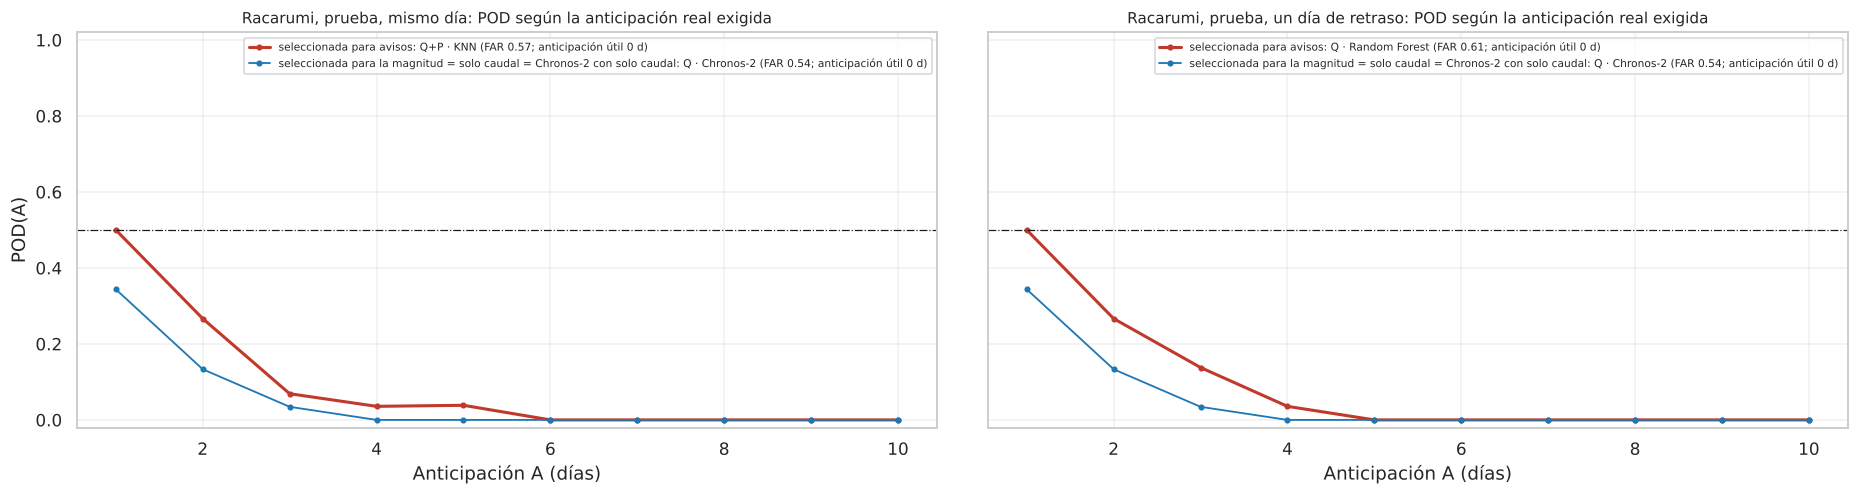

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.6), sharey=True)
for a, esc in zip(ax, I.ESCENARIOS):
    k = SA_E[esc]['elegido']
    # si una misma configuración cumple varios papeles, se dibuja una sola vez con todos sus papeles en la leyenda
    curvas = {}
    for kk, col, et in [(k, '#c0392b', 'seleccionada para avisos'), (CONFIG[('Racarumi', ALC_R, esc)], '#1f77b4', 'seleccionada para la magnitud'),
                        (('Q', 0, SELM['Racarumi'][('Q', 0)]), '#444444', 'solo caudal'), (('Q', 0, CH), I.COLOR[CH], 'Chronos-2 con solo caudal')]:
        curvas.setdefault(kk, [col, []])[1].append(et)
    for kk, (col, papeles) in curvas.items():
        et = ' = '.join(papeles)
        pa, r_ = AVI[(*kk, 'común')]['por_A'], AVI[(*kk, 'común')]['resumen']
        a.plot(pa.index[:10], pa['POD'].iloc[:10], '-o', ms=3, color=col, lw=2 if kk == k else 1.2,
               label=f"{et}: {I.nombre(kk)} (FAR {r_['FAR']:.2f}; anticipación útil {r_['anticipacion_util']} d)")
    a.axhline(AV['pod_min'], color='k', lw=0.8, ls='-.'); a.set_ylim(-0.02, 1.02); a.grid(True, alpha=0.3)
    a.set_title(f'Racarumi, prueba, {esc}: POD según la anticipación real exigida', fontsize=10); a.set_xlabel('Anticipación A (días)'); a.legend(fontsize=7)
ax[0].set_ylabel('POD(A)')
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig06_avisos_racarumi.png', dpi=200, bbox_inches='tight'); plt.show()

**Figura 6.** Racarumi, prueba: fracción de los nuevos cruces del P95 avisados con al menos A días de anticipación real, para la configuración seleccionada para avisos, la seleccionada para la magnitud, solo caudal y Chronos-2 con solo caudal; en la leyenda, la FAR y la anticipación útil (POD(A) ≥ 0.5 con FAR ≤ 0.5).

**Interpretación:**
- **Eventos disponibles:** Racarumi tiene 13 cruces evaluables para calibrar la regla (2009–2011), 14 para comparar candidatos (2012–2015) y 32 en la prueba. **Tamshiyacu tiene 2, 2 y 3 (ninguno en el periodo con Requena): no se selecciona ni se evalúa un sistema de avisos**; afirmar uno sería una selección que los datos no sostienen.
- **Racarumi, selección para avisos:** con los 21 candidatos (incluido Chronos-2), el protocolo común elige **Q+P · KNN** si la lluvia llega el mismo día (CSI 0.68 en 2012–2015, IC de Wilson 0.50–0.83) y **Q · Random Forest** con un día de retraso (0.50); son las mismas elecciones del 06. **Chronos-2 participa como candidato pero no resulta seleccionado**: sus tres configuraciones quedan en CSI 0.38–0.45 en 2012–2015 (puestos 12–20 de 21). Con 14 cruces para comparar, el IC de Wilson del CSI del elegido es ancho (0.50–0.83 y 0.33–0.67): 14 y 11 de los 21 candidatos tienen FAR ≤ 0.5 y un CSI ≥ límite inferior de ese IC. Es un **criterio descriptivo** del rango de incertidumbre del elegido, no una comparación estadística entre modelos (el IC es del CSI del elegido, no de una diferencia pareada) ni una equivalencia: con tan pocos eventos la elección es poco nítida.
- **En la prueba ninguna de las dos cumple el criterio de utilidad:** las dos detectan 16 de 32 cruces, con 21 y 25 falsas alarmas (FAR 0.57 y 0.61) y anticipación útil 0. La mejor configuración observada en la prueba es Q+P · XGBoost (CSI 0.54; 21 de 32 con FAR 0.25, la única que cumple también con los IC), que no fue elegida en validación. Sin separar los bloques, la regla habría elegido Q+P · MLP y Q+P+IA (t−1) · LSTM: **con 27 cruces de validación no se puede elegir de forma confiable un sistema de avisos**.
- **Lo que sí muestra la prueba:** seis configuraciones con la lluvia del mismo día alcanzan 1 día de anticipación útil con los valores puntuales (regresión lineal, XGBoost, MLP y LSTM con Q+P; XGBoost y MLP con Q+P+IA); ninguna con un día de retraso y ninguna de Chronos-2 (10–15 de 32 cruces con FAR 0.52–0.60). Es evidencia retrospectiva de configuraciones evaluadas, no de un sistema seleccionado.

---
## 7. Tabla final del proyecto
Por cuenca, periodo de prueba, disponibilidad de los datos y objetivo: la **configuración seleccionada en validación**, su **desempeño en la prueba** y el **cumplimiento de los criterios de utilidad**, distinguiendo lo seleccionado de lo mejor observado en la prueba. Donde no hay eventos para seleccionar un sistema de avisos se indica en lugar de forzar una elección.

In [16]:
filas = []
for (e, alc, esc), r_ in final_m.iterrows():
    filas.append({'estación': e, 'periodo de prueba': alc, 'escenario': esc, 'objetivo': 'magnitud del caudal',
                  'seleccionada en validación': r_['seleccionada en validación'], 'validación': f"NSE medio {r_['NSE medio validación (2012–2015)']:.3f}; de {r_['candidatos']} candidatos: {r_['equivalentes al mayor en validación (incluido el mayor)']} entre el mayor y sus equivalentes, {r_['inconclusos en validación']} inconclusos",
                  'prueba': f"NSE medio {r_['NSE medio prueba']:.3f}; NSE h=1/7/30 {r_['NSE h=1']:.2f}/{r_['NSE h=7']:.2f}/{r_['NSE h=30']:.2f}; H cota {'≥ ' if r_['H cota 95 % (d)'] >= 30 else ''}{r_['H cota 95 % (d)']} d",
                  'frente a solo caudal': r_['ΔNSE medio frente a solo caudal (IC 90 %)'],
                  'mejor en la prueba (no se elige con él)': r_['mejor NSE medio en la prueba (no se elige con él)'] + ('' if r_['el mejor en prueba coincide con el seleccionado'] else f" · Δ {r_['mejor en prueba frente al seleccionado']}"),
                  'criterio de utilidad': 'H cota 95 % ≥ 1 d', 'cumple': 'sí' if r_['cumple: H cota 95 % ≥ 1 día'] else 'no'})
for (e, alc, esc), r_ in final_a.iterrows():
    filas.append({'estación': e, 'periodo de prueba': alc, 'escenario': esc, 'objetivo': 'anticipación de crecidas',
                  'seleccionada en validación': r_['seleccionada en validación'],
                  'validación': f"CSI 2012–2015 {r_['CSI 2012–2015 (regla de 2009–2011)']:.2f} (IC90 {r_['CSI 2012–2015 IC90 (Wilson)']}; cruces {r_['cruces 2009–2011 / 2012–2015']}); {r_['candidatos con FAR ≤ 0.5 y CSI 2012–2015 ≥ límite inferior del IC90 del seleccionado (criterio descriptivo)']} de {r_['candidatos']} candidatos con CSI ≥ límite inferior de ese IC (criterio descriptivo, no una comparación entre modelos)",
                  'prueba': f"{r_['prueba: aciertos / evaluables']} cruces avisados, {r_['falsas alarmas']} falsas alarmas; POD {r_['POD (IC90)']}; FAR {r_['FAR (IC90)']}; anticipación útil {r_['anticipación útil (d)']} d",
                  'frente a solo caudal': '—', 'mejor en la prueba (no se elige con él)': r_['mejor CSI en la prueba (no se elige con él)'],
                  'criterio de utilidad': 'anticipación útil ≥ 1 d (puntual / con IC)',
                  'cumple': f"{'sí' if r_['cumple: anticipación útil ≥ 1 día'] else 'no'} / {'sí' if r_['cumple también con los IC'] else 'no'}"})
for alc, r_ in cruces.loc['Tamshiyacu'].iterrows():
    for esc in I.ESCENARIOS:
        filas.append({'estación': 'Tamshiyacu', 'periodo de prueba': alc, 'escenario': esc, 'objetivo': 'anticipación de crecidas',
                      'seleccionada en validación': 'no se selecciona',
                      'validación': f"cruces evaluables 2009–2011 / 2012–2015: {int(r_['cruces evaluables 2009–2011 (regla)'])} / {int(r_['cruces evaluables 2012–2015 (comparación)'])}",
                      'prueba': f"cruces evaluables: {int(r_['cruces evaluables en la prueba'])}", 'frente a solo caudal': '—',
                      'mejor en la prueba (no se elige con él)': '—', 'criterio de utilidad': 'no evaluable', 'cumple': 'no evaluable'})
tabla_final = pd.DataFrame(filas).set_index(['estación', 'periodo de prueba', 'escenario', 'objetivo'])
tabla_final.to_csv(RUTA_TAB / 'tabla_final.csv')
tabla_final

seleccionada en validación  \
estación   periodo de prueba                            escenario         objetivo                                              
Racarumi   prueba 2016-01 a 2023-08                     mismo día         magnitud del caudal                   Q · Chronos-2   
                                                        un día de retraso magnitud del caudal                   Q · Chronos-2   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)     mismo día         magnitud del caudal                         Q · KNN   
                                                        un día de retraso magnitud del caudal                         Q · KNN   
           común con Requena (prueba 2016-01 a 2020-03) mismo día         magnitud del caudal                      Q+SR · KNN   
                                                        un día de retraso magnitud del caudal                         Q · KNN   
Racarumi   prueba 2016-01 a 2023-08                     mismo día         anticipación de crecidas                  Q+P · KNN   
                                                        un día de retraso anticipación de crecidas          Q · Random Forest   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)     mismo día         anticipación de crecidas           no se selecciona   
                                                        un día de retraso anticipación de crecidas           no se selecciona   
           común con Requena (prueba 2016-01 a 2020-03) mismo día         anticipación de crecidas           no se selecciona   
                                                        un día de retraso anticipación de crecidas           no se selecciona   

                                                                                                                                                                                                                 validación  \
estación   periodo de prueba                            escenario         objetivo                                                                                                                                            
Racarumi   prueba 2016-01 a 2023-08                     mismo día         magnitud del caudal                                         NSE medio 0.596; de 21 candidatos: 2 entre el mayor y sus equivalentes, 7 inconclusos   
                                                        un día de retraso magnitud del caudal                                         NSE medio 0.596; de 21 candidatos: 2 entre el mayor y sus equivalentes, 7 inconclusos   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)     mismo día         magnitud del caudal                                        NSE medio 0.927; de 42 candidatos: 7 entre el mayor y sus equivalentes, 10 inconclusos   
                                                        un día de retraso magnitud del caudal                                        NSE medio 0.927; de 42 candidatos: 5 entre el mayor y sus equivalentes, 11 inconclusos   
           común con Requena (prueba 2016-01 a 2020-03) mismo día         magnitud del caudal                                       NSE medio 0.929; de 84 candidatos: 13 entre el mayor y sus equivalentes, 12 inconclusos   
                                                        un día de retraso magnitud del caudal                                       NSE medio 0.927; de 84 candidatos: 13 entre el mayor y sus equivalentes, 20 inconclusos   
Racarumi   prueba 2016-01 a 2023-08                     mismo día         anticipación de crecidas  CSI 2012–2015 0.68 (IC90 0.50–0.83; cruces 13 / 14); 14 de 21 candidatos con CSI ≥ límite inferior de ese IC (criter...   
                                                        un día de retraso anticipación de crecidas  CSI 2012–2015 0.50 (IC90 0.33–0.67; cruces 13 / 14); 11 de 21 candidatos con CSI ≥ límite inferior de ese IC (criter...   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)     mismo 

**Interpretación:**
- **Magnitud del caudal:** las seis selecciones cumplen el criterio de utilidad (horizonte útil ≥ 1 día): Racarumi, 5 días con Q · Chronos-2; Tamshiyacu, ≥ 30 días con Q · KNN (con San Regis, prueba 2016-01 a 2025-12) y 17–18 días en el periodo común con Requena (prueba 2016-01 a 2020-03). Pero **ninguna coincide con la mejor de la prueba**, y en Racarumi la elegida es superada con IC > 0 por la mitad de los candidatos.
- **Anticipación de crecidas:** en Racarumi **ninguna configuración elegida en validación cumple** el criterio (ni con los valores puntuales ni con los IC); en Tamshiyacu no hay eventos para evaluar.
- **Disponibilidad:** solo una selección usa una fuente externa (Q+SR · KNN, periodo con Requena, mismo día), y supone que San Regis del día t está disponible al emitir; las demás usan solo el caudal local.
- **Lectura conjunta:** las entradas externas (San Regis, lluvia) reducen el error de corto plazo con el mismo modelo, pero con la regla y la validación disponibles la selección final se queda casi siempre con solo caudal. Esa distancia entre lo que la prueba muestra y lo que la validación permite elegir es el resultado principal de la comparación integrada.

---
## 8. Lo que no entra en la selección
Fuera de la selección: (a) Racarumi con **Cirato** (13 meses: seis modelos con hiperparámetros fijos en el 05, retrospectivo y prospectivo; Chronos-2 en el 07) y (b) el experimento **idealizado de lluvia futura observada** (06 §10 con XGBoost y regresión lineal; 07 §7 con Chronos-2), comparando en las mismas emisiones el pronóstico de Chronos-2 con el de XGBoost y sus avisos en Racarumi: supone conocer la lluvia de los días pronosticados, que en la práctica no se tiene, por eso no compite. Solo esos tres modelos tienen implementado el escenario; no se presenta como evaluado con los seis.

In [17]:
cir = pd.read_csv(SAL / 'aguas_arriba' / 'tablas' / 'tabla_cirato_exploratorio.csv')
q_c = cir[cir['conjunto'] == 'Q+C'].copy()
q_c['G (IC 90 %)'] = q_c.apply(lambda r: f"{r['G frente a Q'] * 100:+.0f} % [{r['IC90 inferior'] * 100:+.0f}, {r['IC90 superior'] * 100:+.0f}] {I.SIG.get(r['lectura'], '')}", axis=1)
tab_cir = q_c.pivot_table(index=['modo', 'h'], columns='modelo', values='G (IC 90 %)', aggfunc='first')[MODELOS]
ch_c = PREVIAS['chronos'].get('cirato', {})
print(f"Chronos-2 con Cirato (07): {ch_c}")
tab_cir

Chronos-2 con Cirato (07): {'emisiones': 197, 'G h1': -0.01, 'lectura h1': 'sin diferencia demostrada'}


modelo            Regresión lineal      Random Forest             XGBoost  \
modo          h                                                             
prospectivo   1   +3 % [-2, +16] ≈   -1 % [-4, +13] ≈   -15 % [-20, +6] ≈   
              2    +1 % [-1, +7] ≈  -15 % [-18, +8] ≈   -14 % [-19, +5] ≈   
              3    +6 % [+3, +8] +   -9 % [-11, +3] ≈   -17 % [-36, -7] −   
retrospectivo 1  +0 % [-24, +14] ≈   +3 % [+1, +14] +    -1 % [-4, +26] ≈   
              2   -3 % [-14, +7] ≈   -9 % [-13, +9] ≈  -16 % [-25, +11] ≈   
              3  +1 % [-18, +13] ≈    -8 % [-9, +4] ≈   -18 % [-25, -1] −   

modelo                         KNN                MLP              LSTM  
modo          h                                                          
prospectivo   1   +4 % [+1, +20] +  +9 % [-31, +27] ≈   +1 % [-2, +1] ≈  
              2    -1 % [-3, +8] ≈   -6 % [-32, +4] ≈   +1 % [-3, +3] ≈  
              3  -12 % [-25, +6] ≈   -6 % [-18, -3] −   +1 % [-3, +6] ≈  
retrospectivo 1   -0 % [-18, +7] ≈  +6 % [-41, +11] ≈   +1 % [-1, +2] ≈  
              2   -6 % [-26, -1] −   -9 % [-42, +0] ≈   +1 % [-4, +4] ≈  
              3  -10 % [-16, -2] −   -8 % [-26, +9] ≈  -3 % [-26, +2] ≈

In [18]:
# Escenario idealizado (lluvia futura observada): mismas emisiones de prueba de 01/02 y 06; no compite en ninguna selección
ZI = np.load(SAL / 'lluvia' / 'predicciones_idealizado.npz')
filas_i, filas_g = [], []
for e in EST:
    fp = pd.DatetimeIndex(ZI[f'{e}_fechas_pru']); obs = ZI[f'{e}_obs_pru'].astype(float)
    pos = pd.DatetimeIndex(ZC[f'{e}|Q+P|idealizado|fechas']).get_indexer(fp)
    assert (pos >= 0).all(), e
    preds = {'XGBoost': ZI[f'{e}_2_xgb_pru'].astype(float), 'Regresión lineal': ZI[f'{e}_2_lineal_pru'].astype(float),
             'Chronos-2': ZC[f'{e}|Q+P|idealizado|punto'][pos].astype(float)}
    for n, pr in preds.items():
        filas_i.append({'estación': e, 'modelo (lluvia futura observada)': n, 'NSE medio': C.nse_medio(pr, obs),
                        **{f'NSE h={h}': C.nse(obs[:, h - 1], pr[:, h - 1]) for h in (1, 7, 30)}})
    _, gb = A.ganancia(fp, obs, preds['Chronos-2'], preds['XGBoost'], B=B)
    for banda, g in gb.iterrows():
        filas_g.append({'estación': e, 'banda': banda, 'G de Chronos-2 frente a XGBoost (IC 90 %)': f"{g['G'] * 100:+.0f} % [{g['IC90 inferior'] * 100:+.0f}, {g['IC90 superior'] * 100:+.0f}] {I.SIG.get(g['lectura'], '')}"})
ideal = pd.DataFrame(filas_i).set_index(['estación', 'modelo (lluvia futura observada)'])
ideal_g = pd.DataFrame(filas_g).pivot(index='estación', columns='banda', values='G de Chronos-2 frente a XGBoost (IC 90 %)')[I.BANDAS]
av_i = pd.concat([pd.read_csv(SAL / 'lluvia' / 'tablas' / 'tabla_idealizado_avisos.csv', index_col=0),
                  pd.read_csv(SAL / 'chronos' / 'tablas' / 'tabla_avisos_idealizado_racarumi.csv', index_col=0)])
display(ideal.round(3))
display(ideal_g)
av_i[['aciertos', 'cruces evaluables', 'falsas alarmas', 'FAR', 'anticipación útil (d)', 'anticipación útil, conjunto fijo (d)']]

NSE medio  NSE h=1  NSE h=7  \
estación   modelo (lluvia futura observada)                                
Racarumi   XGBoost                               0.821    0.934    0.853   
           Regresión lineal                      0.736    0.901    0.725   
           Chronos-2                             0.818    0.900    0.819   
Tamshiyacu XGBoost                               0.930    0.999    0.972   
           Regresión lineal                      0.922    0.999    0.970   
           Chronos-2                             0.888    0.999    0.967   

                                             NSE h=30  
estación   modelo (lluvia futura observada)            
Racarumi   XGBoost                              0.728  
           Regresión lineal                     0.693  
           Chronos-2                            0.812  
Tamshiyacu XGBoost                              0.876  
           Regresión lineal                     0.853  
           Chronos-2                            0.760

banda,1–3 días,4–7 días,8–15 días,16–30 días
estación,,,,
Racarumi,"-60 % [-80, -46] −","-32 % [-45, -19] −","-5 % [-18, +8] ≈","+10 % [-6, +23] ≈"
Tamshiyacu,"-37 % [-44, -30] −","-22 % [-29, -15] −","-29 % [-39, -20] −","-71 % [-90, -53] −"


,aciertos,cruces evaluables,falsas alarmas,FAR,anticipación útil (d),"anticipación útil, conjunto fijo (d)"
configuración,,,,,,
XGBoost · + lluvia futura observada (escenario idealizado),25,32,14,0.358974,17,6
Regresión lineal · + lluvia futura observada (escenario idealizado),24,32,5,0.172414,4,2
Chronos-2 · Q + lluvia futura observada (idealizado),20,32,8,0.285714,9,2


**Interpretación (fuera de la selección):**
- **Cirato (exploratorio):** con los seis modelos (05) y con Chronos-2 (07) no se demostró una reducción del error consistente en los 13 meses con fechas confiables (Chronos-2: −1 % a 1 día, sin diferencia demostrada).
- **Lluvia futura observada (idealizado):** en Racarumi XGBoost (NSE medio 0.821) y Chronos-2 (0.818) quedan a la par en el promedio, pero Chronos-2 tiene **60 % más error a 1–3 días** y 32 % más a 4–7 (IC < 0); a 8–30 días no se distinguen. En Tamshiyacu Chronos-2 es peor en todas las bandas (22–71 % más error). En avisos de Racarumi, XGBoost detecta 25 de 32 cruces (14 falsas alarmas; 6 días de anticipación útil sobre los 32 cruces), la regresión lineal 24 (5; 2 días) y Chronos-2 20 (8; 2 días).
- Es un potencial con una lluvia futura sin error, calculado solo con esos tres modelos; no es una configuración utilizable al emitir.

---
## 9. Matriz de experimentos y registro de verificaciones
(a) La **matriz de experimentos**: cada combinación de entradas y familia por cuenca, con el cuaderno que la genera, la fecha de su ajuste o predicción y cómo se obtuvo en esta ejecución (leída por identidad idéntica o calculada), el periodo de prueba y su papel en las selecciones, y las combinaciones no implementadas o excluidas con el motivo; (b) el **registro de verificaciones** de este cuaderno y de las pruebas automáticas del proyecto (`pruebas_entradas.py`, `pruebas_protocolo.py`, `pruebas_avisos.py`), que comprueban causalidad de las entradas, fronteras de los bloques, muestras pareadas, identidad de la caché y protocolo de avisos.

In [19]:
aud = pd.read_csv(SAL / 'chronos' / 'tablas' / 'tabla_auditoria_cache.csv')
aud_k = {(r['estación'], r['conjunto']): r for _, r in aud.iterrows()}
reg_k = {(r['estación'], r['conjunto'], r['modelo']): r for _, r in registro.iterrows()}
# Una configuración puede elegirse en varias selecciones (cuenca × periodo × escenario): se listan todas
sel_m, sel_a = {}, {}
for (e, alc, esc), k in CONFIG.items():
    sel_m.setdefault((e, k), []).append(f'{alc} · {esc}')
for esc, sa in SA_E.items():
    sel_a.setdefault(('Racarumi', sa['elegido']), []).append(f'{ALC_R} · {esc}')
def cuando(t):
    return f'{t:%Y-%m-%d %H:%M}'
filas = []
for e in EST:
    for conj, lat in X[e].conjuntos:
        etq = I.etiqueta(conj, lat)
        periodo = ' y '.join(alc for (e2, alc), (ok, ip) in ALCANCES.items() if e2 == e and ok(conj))
        for n in CAND_M:
            k = (conj, lat, n)
            if n == CH:
                a = aud_k[(e, etq)]
                t_ = datetime.strptime(a['archivo creado'], '%Y-%m-%d %H:%M')
                estado = (f"predicción del 07 ({cuando(t_)}), reutilizada tras verificar identidad, contenido y reproducción"
                          if bool(a['reutilizada (identidad, contenido y reproducción verificados)']) else f'predicción del 07 calculada en esta ejecución ({cuando(t_)})')
                nb = '07'
            else:
                r_ = reg_k[(e, etq, n)]
                nb = r_['cuaderno que lo entrena']
                d_ = X[e].D[(conj, lat)]
                ruta_c = EN._ruta(EN.clave_cache(d_, n, list(C.SEMILLAS if n in C.ESTOCASTICOS else [C.SEMILLA])))
                t_ = datetime.fromtimestamp(ruta_c.stat().st_mtime)
                estado = (f'ajuste guardado ({cuando(t_)}), leído por identidad completa idéntica' if r_['leído de la caché'] else f'ajustado en esta ejecución ({cuando(t_)})')
            filas.append({'estación': e, 'combinación': etq, 'familia': n, 'cuaderno que lo genera': nb, 'estado': estado,
                          'periodos de prueba en que compite': periodo,
                          'escenario': 'ambos (sin fuentes externas)' if conj == 'Q' else ('un día de retraso' if lat else 'mismo día'),
                          'seleccionada para la magnitud': '; '.join(sel_m.get((e, k), [])), 'seleccionada para avisos': '; '.join(sel_a.get((e, k), []))})
NO_IMPL = [('Racarumi', 'Q+Pd (control)', 'seis modelos', '06', 'excluido de la selección: control de representación (mismas fuentes y disponibilidad que Q+P, otra representación de la lluvia)'),
           ('Racarumi', 'combinaciones con Cirato', 'seis modelos y Chronos-2', '05 / 07', 'exploratorio: 13 meses con fechas confiables, sin entrenamiento ni validación del protocolo'),
           ('Racarumi y Tamshiyacu', 'Q+P con lluvia futura observada', 'XGBoost y regresión lineal (06); Chronos-2 (07)', '06 / 07', 'idealizado: supone la lluvia futura conocida; excluido de la selección'),
           ('Racarumi y Tamshiyacu', 'índices antecedentes sin la lluvia (Q+IA, …)', 'todas', '—', 'no implementado por diseño: IA se agrega sobre P para medir su aporte adicional a los acumulados'),
           ('Tamshiyacu', 'avisos con Requena', 'todas', '—', 'no evaluable: el periodo común con Requena (2016-01 a 2020-03) no tiene nuevos cruces del P95'),
           ('Tamshiyacu', 'Q, Q+P y Q+P+IA en todas las emisiones (sin exigir San Regis)', 'seis modelos y Chronos-2', '06', 'otra muestra (más emisiones): se informa en el 06 y no se compara aquí')]
for e, c, f, nb, mot in NO_IMPL:
    filas.append({'estación': e, 'combinación': c, 'familia': f, 'cuaderno que lo genera': nb, 'estado': mot, 'periodos de prueba en que compite': '—', 'escenario': '—',
                  'seleccionada para la magnitud': '', 'seleccionada para avisos': ''})
matriz = pd.DataFrame(filas)
matriz.to_csv(RUTA_TAB / 'tabla_matriz_experimentos.csv', index=False)
imp = matriz[matriz['periodos de prueba en que compite'] != '—']
# Las etiquetas de selección de la matriz deben reproducir exactamente CONFIG y SA_E (una entrada por selección)
verificar('etiquetas', 'la matriz lista cada selección (cuenca × periodo × escenario) exactamente una vez',
          sum(len(v.split('; ')) for v in imp['seleccionada para la magnitud'] if v) == len(CONFIG)
          and sum(len(v.split('; ')) for v in imp['seleccionada para avisos'] if v) == len(SA_E), f'{len(CONFIG)} de magnitud, {len(SA_E)} de avisos')
display(imp.assign(estado=lambda t: t['estado'].str.replace(r' \(2026-\d\d-\d\d \d\d:\d\d\)', '', regex=True))
        .groupby(['estación', 'cuaderno que lo genera', 'estado']).size().rename('combinaciones × familias').to_frame())
display(imp[(imp['seleccionada para la magnitud'] != '') | (imp['seleccionada para avisos'] != '')]
        .set_index(['estación', 'combinación', 'familia'])[['seleccionada para la magnitud', 'seleccionada para avisos']])
matriz[matriz['periodos de prueba en que compite'] == '—'].set_index(['estación', 'combinación'])[['familia', 'cuaderno que lo genera', 'estado']]

combinaciones × familias
estación   cuaderno que lo genera estado                                                                                                     
Racarumi   06                     ajuste guardado, leído por identidad completa idéntica                                                   30
           07                     predicción del 07, reutilizada tras verificar identidad, contenido y reproducción                         5
Tamshiyacu 05                     ajuste guardado, leído por identidad completa idéntica                                                   42
           07                     predicción del 07, reutilizada tras verificar identidad, contenido y reproducción                        23
           08                     ajuste guardado, leído por identidad completa idéntica                                                   96

seleccionada para la magnitud  \
estación   combinación familia                                                                                                                                  
Racarumi   Q           Random Forest                                                                                                                            
                       Chronos-2                                           prueba 2016-01 a 2023-08 · mismo día; prueba 2016-01 a 2023-08 · un día de retraso   
           Q+P         KNN                                                                                                                                      
Tamshiyacu Q           KNN            con San Regis (prueba 2016-01 a 2025-12) · mismo día; con San Regis (prueba 2016-01 a 2025-12) · un día de retraso; ...   
           Q+SR        KNN                                                                           común con Requena (prueba 2016-01 a 2020-03) · mismo día   

                                                          seleccionada para avisos  
estación   combinación familia                                                      
Racarumi   Q           Random Forest  prueba 2016-01 a 2023-08 · un día de retraso  
                       Chronos-2                                                    
           Q+P         KNN                    prueba 2016-01 a 2023-08 · mismo día  
Tamshiyacu Q           KNN                                                          
           Q+SR        KNN

familia  \
estación              combinación                                                                                                      
Racarumi              Q+Pd (control)                                                                                    seis modelos   
                      combinaciones con Cirato                                                              seis modelos y Chronos-2   
Racarumi y Tamshiyacu Q+P con lluvia futura observada                                XGBoost y regresión lineal (06); Chronos-2 (07)   
                      índices antecedentes sin la lluvia (Q+IA, …)                                                             todas   
Tamshiyacu            avisos con Requena                                                                                       todas   
                      Q, Q+P y Q+P+IA en todas las emisiones (sin exigir San Regis)                         seis modelos y Chronos-2   

                                                                                    cuaderno que lo genera  \
estación              combinación                                                                            
Racarumi              Q+Pd (control)                                                                    06   
                      combinaciones con Cirato                                                     05 / 07   
Racarumi y Tamshiyacu Q+P con lluvia futura observada                                              06 / 07   
                      índices antecedentes sin la lluvia (Q+IA, …)                                       —   
Tamshiyacu            avisos con Requena                                                                 —   
                      Q, Q+P y Q+P+IA en todas las emisiones (sin exigir San Regis)                     06   

                                                                                                                                                                                                      estado  
estación              combinación                                                                                                                                                                             
Racarumi              Q+Pd (control)                                                 excluido de la selección: control de representación (mismas fuentes y disponibilidad que Q+P, otra representación de...  
                      combinaciones con Cirato                                                                   exploratorio: 13 meses con fechas confiables, sin entrenamiento ni validación del protocolo  
Racarumi y Tamshiyacu Q+P con lluvia futura observada                                                                                 idealizado: supone la lluvia futura conocida; excluido de la selección  
                      índices antecedentes sin la lluvia (Q+IA, …)                                          no implementado por diseño: IA se agrega sobre P para medir su aporte adicional a los acumulados  
Tamshiyacu            avisos con Requena                                                                       no evaluable: el periodo común con Requena (2016-01 a 2020-03) no tiene nuevos cruces del P95  
                      Q, Q+P y Q+P+IA en todas las emisiones (sin exigir San Regis)                                                   otra muestra (más emisiones): se informa en el 06 y no se compara aquí

In [20]:
# Comprobaciones estructurales de las comparaciones
for (e, alc, esc), s_ in SELS.items():
    n_sel = {len(P[e][k]['sel']) for k in s_['tabla'].index.map({I.nombre(k): k for k in P[e]}.get)}
    verificar('muestras comparables', f'{e} · {alc} · {esc}: todos los candidatos de la selección en las mismas emisiones de validación', n_sel == {len(X[e].VC.sel)}, f'{len(s_["tabla"])} candidatos, {len(X[e].VC.sel)} emisiones')
for (e, alc), (ok, ip) in ALCANCES.items():
    verificar('muestras comparables', f'{e} · {alc}: métricas de prueba de todos los candidatos en las mismas emisiones',
              set(prueba[(prueba['estación'] == e) & (prueba['periodo de prueba'] == alc)]['emisiones']) == {len(ip)}, f'{len(ip)} emisiones')
# Se repiten TODAS las selecciones con los pronósticos de prueba
# reemplazados por ruido; si la prueba interviniera en alguna, cambiaría. Control negativo: si se degrada la validación
# de la configuración elegida, la selección sí cambia (el control puede fallar).
rng = np.random.default_rng(C.SEMILLA)
ruido = lambda a: None if a is None else (rng.lognormal(0.0, 1.0, np.shape(a)) * np.nanmean(a)).astype(np.asarray(a).dtype)
PZ = {e: {k: {**v, **{c: ruido(v[c]) for c in ('pru', 'prumed', 'ext')}} for k, v in P[e].items()} for e in EST}
cambios = []
for (e, alc), (ok, ip) in ALCANCES.items():
    for esc in I.ESCENARIOS:
        cand = [k for k in P[e] if ok(k[0]) and I.en_escenario(k[0], k[1], esc)]
        if I.seleccion_configuracion(X[e], PZ[e], cand, B=B)['elegida'] != CONFIG[(e, alc, esc)]:
            cambios.append(f'magnitud {e} · {alc} · {esc}')
for e in EST:
    if I.seleccion_por_conjunto(X[e], PZ[e], modelos=CAND_M, B=B)[0] != SELM[e]:
        cambios.append(f'modelo por combinación {e}')
# para avisos, también los caudales observados posteriores al último objetivo de validación pasan a ser ruido
fin_obj = xR.fechas_val.max() + pd.Timedelta(days=len(C.HORIZONTES))
qz = xR.F.q.copy(); post = qz.index > fin_obj
qz[post] = rng.permutation(qz[post].to_numpy()) * 3.0
xRz = dataclasses.replace(xR, F=dataclasses.replace(xR.F, q=qz))
for esc in I.ESCENARIOS:
    if I.seleccion_avisos(xRz, PZ['Racarumi'], [k for k in PRr if I.en_escenario(k[0], k[1], esc)])['elegido'] != SA_E[esc]['elegido']:
        cambios.append(f'avisos Racarumi · {esc}')
(e0, a0, s0), k0 = next(iter(CONFIG.items()))
P_neg = {**P[e0], k0: {**P[e0][k0], 'sel': P[e0][k0]['sel'] * 0 + np.nanmean(P[e0][k0]['sel'])}}
ok0 = ALCANCES[(e0, a0)][0]
detecta = I.seleccion_configuracion(X[e0], P_neg, [k for k in P[e0] if ok0(k[0]) and I.en_escenario(k[0], k[1], s0)], B=B)['elegida'] != k0
verificar('separación temporal', 'la prueba no interviene en ninguna selección: con la prueba reemplazada por ruido, las selecciones no cambian',
          not cambios and detecta, (', '.join(cambios) or f'{len(CONFIG)} selecciones de magnitud, {len(EST)} de modelo por combinación y {len(SA_E)} de avisos iguales')
          + f'; control negativo (validación degradada de {I.nombre(k0)}) cambia la selección: {detecta}')
verificar('separación temporal', 'emisiones de validación anteriores a la prueba y de entrenamiento anteriores a la validación',
          all(X[e].m.fechas[X[e].p['ent']].max() < X[e].fechas_val.min() and X[e].fechas_val.max() < X[e].m.fechas[X[e].p['pru']].min() for e in EST))
verificar('separación temporal', 'los objetivos del bloque de Duan terminan antes del bloque de selección',
          all((X[e].fechas_val[X[e].VC.cal] + pd.Timedelta(days=len(C.HORIZONTES))).max() < X[e].VC.fechas_sel.min() for e in EST))
# Pruebas automáticas del proyecto (fase previa: no dependen de las salidas)
for script in ['pruebas_entradas.py', 'pruebas_protocolo.py', 'pruebas_avisos.py']:
    t0 = time.time()
    out = subprocess.run([sys.executable, script], capture_output=True, text=True, cwd=Path.cwd(),
                         env={k: v for k, v in os.environ.items() if k != 'CDA_RAPIDO'})
    ult = (out.stdout.strip().splitlines() or ['sin salida'])[-1]
    verificar('pruebas automáticas', script, out.returncode == 0, f'{ult} ({time.time() - t0:,.0f} s)')
verif = pd.DataFrame(VERIF)
verif.to_csv(RUTA_TAB / 'tabla_registro_verificaciones.csv', index=False)
print(f"{(verif['resultado'] == 'correcto').sum()} de {len(verif)} verificaciones correctas")
verif.set_index(['grupo', 'comprobación'])

39 de 39 verificaciones correctas


resultado  \
grupo                      comprobación                                                                                                                         
correspondencia de fechas  Racarumi: validación = cuaderno 06                                                                                        correcto   
                           Racarumi: bloque de selección = cuaderno 06                                                                               correcto   
                           Racarumi: prueba = cuaderno 06                                                                                            correcto   
                           Tamshiyacu: validación = cuaderno 05                                                                                      correcto   
                           Tamshiyacu: bloque de selección = cuaderno 05                                                                             correcto   
                           Tamshiyacu: prueba = cuaderno 05                                                                                          correcto   
                           Tamshiyacu: prueba común con Requena = cuaderno 05                                                                        correcto   
etiquetas                  cada periodo de prueba se nombra con el primer y el último mes de sus emisiones                                           correcto   
reutilización              pronósticos de 05 y 06 reconstruidos = guardados (float32)                                                                correcto   
Chronos-2                  predicción del 07 para cada combinación del experimento                                                                   correcto   
                           sus fechas cubren el bloque de selección y cada periodo de prueba en que compite la combinación                           correcto   
                           pronósticos sin fechas duplicadas, finitos y con P10 ≤ mediana ≤ P90                                                      correcto   
                           el 07 validó contenido y reproducción de cada caché reutilizada                                                           correcto   
entradas reales            cada combinación tiene ficha de las seis familias y de Chronos-2 (tabla del 07)                                           correcto   
                           Chronos-2 recibe como covariable cada fuente externa de la combinación (y solo esas)                                      correcto   
coherencia entre cuadernos Racarumi, mismo día: la selección con los candidatos del 06 reproduce la del 06                                           correcto   
                           Tamshiyacu con San Regis (prueba 2016-01 a 2025-12), mismo día: la selección con los candidatos del 05 reproduce la d...  correcto   
                           Tamshiyacu común con Requena (prueba 2016-01 a 2020-03), mismo día: la selección con los candidatos del 05 reproduce ...  correcto   
                           Racarumi, un día de retraso: la selección con los candidatos del 06 reproduce la del 06                                   correcto   
                           Tamshiyacu con San Regis (prueba 2016-01 a 2025-12), un día de retraso: la selección con los candidatos del 05 reprod...  correcto   
                           Tamshiyacu común con Requena (prueba 2016-01 a 2020-03), un día de retraso: la selección con los candidatos del 05 re...  correcto   
muestras comparables       Tamshiyacu común con Requena (prueba 2016-01 a 2020-03): efectos de cada fuente en las mismas 1093 emisiones              correcto   
avisos                     Racarumi: todos los candidatos tienen trayectoria mediana en toda la validación                                           correcto   
etiquetas                  la matriz lista cada selección (cuenca × periodo × escenario) exactamente una vez               

---
## 10. Salidas y resumen
Archivos de salida: la tabla maestra (cada candidato con su NSE medio de selección y de prueba, horizonte útil y papel en las selecciones), los pronósticos de prueba de todos los candidatos (`salidas/entradas/predicciones_racarumi.npz` y `predicciones_tamshiyacu.npz`, mismo formato que 05 y 06, sin las predicciones de validación) y el resumen para la síntesis (`salidas/entradas/resumen.json`).

In [21]:
maestra = pmod.merge(val[['estación', 'conjunto', 'modelo', 'NSE medio selección']], on=['estación', 'conjunto', 'modelo'], how='left')
maestra['seleccionada para la magnitud'] = [', '.join(f'{alc} · {esc}' for (e, alc, esc), k in CONFIG.items() if e == r['estación'] and alc == r['periodo de prueba']
                                                      and I.nombre(k) == f"{r['conjunto']} · {r['modelo']}") for _, r in maestra.iterrows()]
maestra.to_csv(RUTA_TAB / 'tabla_maestra.csv', index=False)
# Pronósticos de prueba (media y mediana) de los 140 candidatos, un archivo por estación (límite de tamaño de GitHub); las
# predicciones de validación de los ajustes reutilizados ya están en las salidas de 05, 06 y 07
for e in EST:
    g = {k: v for k, v in I.claves_npz(X[e], P[e]).items() if not k.endswith(('|sel', '|valmed'))}
    np.savez_compressed(RUTA_SAL / f'predicciones_{e.lower()}.npz', **g)
limpio = lambda v: None if isinstance(v, float) and not np.isfinite(v) else (bool(v) if isinstance(v, (np.bool_,)) else (int(v) if isinstance(v, np.integer) else v))
resumen = {
    'version': C.VERSION, 'revision': C.REVISION, 'rapido': RAPIDO, 'etapa': 'comparación integrada y selección final (cuaderno 08)',
    'experimento': EN.VERSION_EXPERIMENTO, 'huella_codigo_ajuste': EN.huella_codigo(),
    'candidatos': {e: {'combinaciones': [I.etiqueta(c, l) for c, l in X[e].conjuntos], 'familias': CAND_M} for e in EST},
    'chronos': {'contexto': [str(v) for v in ZC['contexto']], 'punto': [str(v) for v in ZC['punto']]},
    'seleccion_magnitud': {f'{e}|{alc}|{esc}': {k_: limpio(v_) for k_, v_ in r_.items()} for (e, alc, esc), r_ in final_m.to_dict('index').items()},
    'seleccion_avisos': {f'{e}|{alc}|{esc}': {k_: limpio(v_) for k_, v_ in r_.items()} for (e, alc, esc), r_ in final_a.to_dict('index').items()},
    'cruces_evaluables': {f'{e}|{alc}': {k_: limpio(v_) for k_, v_ in r_.items()} for (e, alc), r_ in cruces.to_dict('index').items()},
    'mayor_y_equivalentes_magnitud': {f'{e}|{alc}|{esc}': [I.nombre(k) for k in v] for (e, alc, esc), v in EQUIV.items()},
    'inconclusos_magnitud': {f'{e}|{alc}|{esc}': [I.nombre(k) for k in v if k not in EQUIV[(e, alc, esc)]] for (e, alc, esc), v in NOPEOR.items()},
    'periodos_de_prueba': {e: [alc for (e2, alc) in ALCANCES if e2 == e] for e in EST},
    'modelo_por_conjunto': {e: {I.etiqueta(*k): v for k, v in SELM[e].items()} for e in EST},
    'nse_medio_prueba': {f"{r['estación']}|{r['periodo de prueba']}|{r['conjunto']}|{r['modelo']}": round(float(r['NSE medio']), 4) for _, r in pmod.iterrows()},
    'h_cota_prueba': {f"{r['estación']}|{r['periodo de prueba']}|{r['conjunto']}|{r['modelo']}": int(r['H cota 95 % (d)']) for _, r in pmod.iterrows()},
    'matriz': {'combinaciones_x_familias': int((matriz['periodos de prueba en que compite'] != '—').sum()),
               'leidas_por_identidad': int(matriz['estado'].str.contains('leído|reutilizada').sum()),
               'calculadas_en_esta_ejecucion': int(matriz['estado'].str.contains('esta ejecución').sum()),
               'no_implementadas_o_excluidas': len(NO_IMPL)},
    'verificaciones': {'total': len(verif), 'correctas': int((verif['resultado'] == 'correcto').sum())},
    'minutos': round((time.time() - T_INICIO) / 60, 1),
}
(RUTA_SAL / 'resumen.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print(json.dumps({k: resumen[k] for k in ['matriz', 'verificaciones', 'minutos']}, ensure_ascii=False, indent=1))

{
 "matriz": {
  "combinaciones_x_familias": 196,
  "leidas_por_identidad": 196,
  "calculadas_en_esta_ejecucion": 0,
  "no_implementadas_o_excluidas": 6
 },
 "verificaciones": {
  "total": 39,
  "correctas": 39
 },
 "minutos": 12.6
}


---
## 11. Conclusiones

1. **La comparación integrada se completó en las mismas emisiones para todas las combinaciones disponibles:** 28 combinaciones de entradas (5 en Racarumi; en Tamshiyacu, las 12 combinaciones de lluvia, índices, San Regis y Requena, con las fuentes hasta t y hasta t−1: 23) × 7 familias = 196 candidatos; 168 ajustes de los seis modelos (72 reutilizados de 05 y 06 con pronósticos idénticos a los guardados y 96 propios del 08) y 28 predicciones de Chronos-2 verificadas por identidad, contenido y reproducción de una muestra. Las 39 verificaciones son correctas; entre ellas, que las selecciones no cambian si la prueba se reemplaza por ruido (con un control negativo que sí cambia) y que Chronos-2 cubre explícitamente cada bloque y periodo en que compite. Quedan fuera solo las combinaciones excluidas por diseño (índices sin lluvia, Cirato, control Q+Pd, idealizado).
2. **Selección final para la magnitud (validación 2012–2015):**
   - **Racarumi (prueba 2016-01 a 2023-08): Q · Chronos-2** en los dos escenarios de disponibilidad. **En la prueba no se sostiene** (NSE medio 0.490, horizonte útil de 5 días): 10 de los 20 demás candidatos son mejores con IC > 0, y el mejor observado es Q+P+IA · LSTM (0.541), que usa la lluvia del mismo día.
   - **Tamshiyacu con San Regis (prueba 2016-01 a 2025-12): Q · KNN** (0.906, ≥ 30 días); el mejor de la prueba, Q+P+SR · MLP, es apenas mejor (+0.016).
   - **Tamshiyacu común con Requena (prueba 2016-01 a 2020-03):** Q+SR · KNN si San Regis llega el mismo día (0.855, 18 días; 28 % menos error a 1–3 días que Q · KNN) y Q · KNN con un día de retraso. Completar las combinaciones de lluvia con Requena no cambió la selección: la mejor de ellas en validación (Q+P+SR+RQ · XGBoost) es equivalente a Q+SR · KNN, que es más simple.
3. **Selección final para la anticipación de crecidas:** Racarumi, **Q+P · KNN** (lluvia el mismo día) y **Q · Random Forest** (un día de retraso); **ninguna cumple el criterio de utilidad en la prueba**. Tamshiyacu: **no se selecciona** (3 cruces en la prueba con San Regis, ninguno en el periodo común con Requena).
4. **Chronos-2, como candidato efectivo:** en magnitud resulta seleccionado en Racarumi por su ventaja en validación (0.596 frente a 0.565 de la mejor familia entrenada), pero **no mantiene esa ventaja relativa en la prueba** (10 de los 20 demás candidatos son mejores con IC > 0); en Tamshiyacu es peor que la configuración seleccionada en 34 de 36 comparaciones (con el contexto de 512 días elegido en validación). **En avisos participa como candidato en los dos escenarios, pero no resulta seleccionado** (CSI 0.38–0.45 en 2012–2015; en la prueba, 10–15 de 32 cruces con FAR 0.52–0.60). Recibe las mismas fuentes y disponibilidad que los modelos entrenados, con su propia representación: series diarias en unidades físicas dentro de su contexto.
5. **Lo que se puede afirmar sin depender de la selección:** con el mismo modelo, San Regis reduce el error de Tamshiyacu en la primera semana y la lluvia en la segunda a cuarta (también sobre Requena); Requena no agrega a las familias entrenadas; la lluvia del mismo día reduce el error y permite 1 día de aviso en Racarumi con varias configuraciones evaluadas; con un día de retraso de las fuentes externas casi todo eso se pierde en Racarumi y se conserva en Tamshiyacu (salvo San Regis, que pierde la mayor parte).
6. **Respuesta del proyecto (comparación académica de configuraciones, no un sistema operativo de alerta):** con la información disponible y una selección honesta en validación, el aviso que dan estos ríos es corto: en Racarumi, pronósticos de magnitud útiles a 5–7 días y ningún sistema de avisos elegido de antemano que cumpla el criterio; en Tamshiyacu, magnitud útil a ≥ 30 días y avisos no evaluables. Las ganancias de las entradas externas son reales con el mismo modelo, pero la validación disponible no basta para elegirlas de forma confiable. Lo que aquí se llama «sistema de avisos» es una configuración (modelo, entradas y regla de aviso) evaluada retrospectivamente, no un sistema operativo de alerta: para eso faltarían datos en tiempo real, más eventos y una validación prospectiva.

### Limitaciones
- **Selecciones poco nítidas:** para la magnitud, entre 1 y 12 candidatos son equivalentes al mayor y entre 7 y 20 quedan inconclusos según la selección; para avisos, 11 y 14 de 21 candidatos tienen un CSI ≥ límite inferior del IC del seleccionado (criterio descriptivo). Cada IC es individual y no se corrigió por comparaciones múltiples. El contexto de Chronos-2 se eligió en el mismo bloque de selección.
- **Representaciones distintas:** todas las familias reciben las mismas fuentes con la misma disponibilidad, pero cada una con su representación (tabulares: nivel, cambios y acumulados en logaritmos; KNN: ventana elegida; LSTM: canales diarios de 30 días; Chronos-2: series diarias en unidades físicas con 512 o 2 048 días de contexto). Una diferencia entre familias no aísla el efecto del algoritmo.
- **Disponibilidad supuesta:** el escenario «mismo día» supone que la lluvia y San Regis del día t se conocen al emitir; no está demostrado.
- **Escasez de eventos:** 13 y 14 cruces en los bloques de validación de Racarumi y 32 en la prueba; 2, 2 y 3 en Tamshiyacu (0 en el periodo común con Requena).
- **Uso previo de la prueba:** el periodo de prueba (desde 2016-01) se consultó durante el desarrollo del proyecto con casi todas estas entradas; las reglas se fijaron antes de la evaluación final y la prueba no intervino en ninguna selección (comprobado reemplazándola por ruido), pero no es una prueba ciega.
- **Muestras distintas no comparadas:** Tamshiyacu con todas las emisiones (06) y con San Regis (05, 08); el periodo común con Requena frente al periodo con San Regis.
- **No implementado por diseño:** índices antecedentes sin la lluvia; Cirato solo exploratorio.